# Task A（`taskA-gemini`）：自然语言数学加减法应用题生成与校准（`Qwen/Qwen3-4B`）

本 Notebook 在 `taskA-gemini` 分支全新实现 **自然语言数学加减法应用题（`math_word_v1`）** 的确定性生成、独立求解器校验、双向难度搜索与 7 深度斜率校准，以及人工审核门控后的 3000 题正式数据集交付。

## 1. 设计背景与对 `cursor` 分支 DA 低正确率问题的根因修正

| 维度 | `cursor` 分支旧方案的问题 | 本分支（`math_word_v1`）的新设计 |
|---|---|---|
| **题型结构** | 每步强制嵌入 `if v > T ... otherwise ...` 阈值分支 + 正反极性随机翻转 + `100%` 无关干扰数字句，`d=1` 即含 5 个数字，单次前向需同时完成「过滤干扰 → 极性解码 → 两位数比较 → 分支路由 → 进退位加减」，导致 `DA(1)` 仅 `0.10~0.70`、`DA(2)` 断崖跌至 `0.08` | **回归纯粹自然语言串行加减法应用题**（日常物品收集、门店/烘焙库存、图书借阅、计量物资、零花钱收支）：每一步恰好对应一个无歧义的自然语言增减事件，仅含 1 个变化量数字，无 `if/else` 逻辑锁、无无关干扰句、无 `min/max` 聚合、无乘除取模 |
| **模型选择** | 早期使用 `Qwen3-4B-Instruct-2507` | 统一使用 **`Qwen/Qwen3-4B`**（混合推理模型，非 Base、非 Instruct-2507），显式设置 **`enable_thinking=False`** 关闭内置 `<think>` 块，保证 `DA` 与 `CoT` 纯粹由提示词控制 |
| **DA/CoT 对称与防泄漏** | 零样本 `Solve silently` 导致大量回写初值；无预填时 54%+ 泄漏为截断 CoT；单侧给 DA 加 4-shot 破坏输入对称 | **DA / CoT 对称 2-shot 示例**（共享来自独立 `fewshot` 划分的 1 加 1 减两道 `d=1` 题）+ **DA 端 `continue_final_message=True` 续写 `"#### "` 预填**：`<think>\n\n</think>\n\n#### ` 后直接生成答案并自然结束，无需 `stop=['\n']` 硬截断即可实现零泄漏、零截断；主表同时报告 **严格单行正确率 `strict_da_ok`** 与整体正确率 `answer_ok` |
| **难度梯度覆盖** | 单一整数配置，缺少双向自动搜参 | 内置 **5 档同构自然语言加减配置阶梯**（`word_int1_easy` → `word_int2_carry` → `word_int3_carry` → `word_dec1_carry` → `word_dec2_money`），支持双向搜索兼顾 `DA(d=1) ≥ 0.80`、低深度 DA 平滑衰减（实测覆盖 `d ∈ {1,2,3,5,10,15,20}`）与 `CoT(d=20) ∈ [0.40, 0.75]` |

---

## 2. Colab 快速运行指南

1. 在 Colab 打开本文件：**`Experiments/task_a_math_word/experiment_task_a_word.ipynb`**（从 `taskA-gemini` 分支打开）。
2. 菜单选择 **「代码执行程序 → 更改运行时类型」**，硬件加速器选 **L4 GPU**（推荐，`bfloat16` 批处理最快）或 **T4 GPU**（自动启用 `float16` 兼容参数）。
3. 直接点击 **「全部运行（Run all）」**：
   - 默认 `RUN_STAGE = "search"`：从 `word_int2_carry` 起步，若 `DA(d=1) < 0.80` 自动下探更易档 `word_int1_easy`；若 `DA(d=1) ≥ 0.80` 则快速筛查 `CoT(d=20)`，偏易时沿阶梯上探（`int3` → `dec1` → `dec2`），随后自动在独立 `slope` 划分上跑完 **7 个深度 `d ∈ {1, 2, 3, 5, 10, 15, 20}` × 30 题 × DA/CoT = 420 次推理**。
   - 运行结束自动绘制深度曲线图 `task_a_word_calibration.png`，打包并触发浏览器下载 `task_a_word_results.zip`。
4. **人工审查提醒（`task.md` A.0 硬性流程）**：
   - 拿到校准结果后，**请开发者务必进行人工审查**（核查各深度严格 DA 正确率、CoT 错误类型分布与原文样例），不要不经审查直接把候选当成正式数据集。
   - 人工确认后，将审查结论写入 `Experiments/task_a_math_word/task_a_word_human_review.json`，再开启 `GENERATE_FINAL = True` 生成正式 3000 题（串行 2000 + `W` 配平并行 1000）。


In [1]:
import hashlib
import importlib.metadata
import importlib.util
import json
import math
import os
import random
import re
import sys
import tempfile
import time
import zipfile
from collections import Counter, defaultdict
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from decimal import Decimal, InvalidOperation
from pathlib import Path


def project_root() -> Path:
    if os.environ.get("TASK_A_WORD_ROOT"):
        root = Path(os.environ["TASK_A_WORD_ROOT"]).expanduser().resolve()
        root.mkdir(parents=True, exist_ok=True)
        return root
    for parent in (Path.cwd(), *Path.cwd().parents):
        if (parent / "task.md").is_file() or (parent / "pyproject.toml").is_file():
            return parent
    content = Path("/content")
    colab_repo = content / "CISC7404-Project"
    if (colab_repo / "task.md").is_file():
        return colab_repo
    if content.is_dir():
        root = content / "taskA_word"
        root.mkdir(parents=True, exist_ok=True)
        print(f"未检测到完整仓库，使用 Colab 独立实验目录：{root}（会话结束后临时目录会清空，请保留自动下载的 ZIP 结果包）。")
        return root
    raise RuntimeError("请切到仓库目录，或先设置 os.environ['TASK_A_WORD_ROOT'] = '可写目录'。")


ROOT = project_root()
EXP_DIR = ROOT / "Experiments" / "task_a_math_word"
WORK_DIR = ROOT / "work" / "task_a_math_word"
EXP_DIR.mkdir(parents=True, exist_ok=True)
WORK_DIR.mkdir(parents=True, exist_ok=True)

RESULT_PATH = EXP_DIR / "calib_v4_math_word.jsonl"
DIAGNOSTIC_PATH = EXP_DIR / "task_a_word_diagnostic.jsonl"
PROBE_REPORT_PATH = EXP_DIR / "task_a_word_probe_summary.json"
SEARCH_REPORT_PATH = EXP_DIR / "task_a_word_search_summary.json"
SLOPE_REPORT_PATH = EXP_DIR / "task_a_word_summary.json"
DIAGNOSTIC_REPORT_PATH = EXP_DIR / "task_a_word_diagnostic_summary.json"
PLOT_PATH = EXP_DIR / "task_a_word_calibration.png"
REVIEW_PATH = EXP_DIR / "task_a_word_human_review.json"
EXPORT_MANIFEST_PATH = EXP_DIR / "task_a_word_export_manifest.json"
EXPORT_ZIP_PATH = WORK_DIR / "task_a_word_results.zip"
DATA_PATH = ROOT / "Experiments" / "data_generation" / "synthesis_math_word_dataset.jsonl"
FINAL_VALIDATION_PATH = EXP_DIR / "task_a_word_final_validation.json"

# ---- 实验版本与网格配置 ----
VERSION = "math_word_v1"
PROMPT_VERSION = "qwen3_4b_sym2shot_prefill_v1"
SEED = 7404

# 覆盖 d=2,3 以精细观测低深度 DA 衰减曲线，同时对齐 d=1,5,10,15,20 主网格
D_LIST = (1, 2, 3, 5, 10, 15, 20)
N_PROBE = 100          # 探针：d=1 × 100 题 × DA
N_SCREEN_COT20 = 25    # 搜索阶段快速锚定：d=20 × 25 题 × CoT
N_SLOPE = 30           # 斜率阶段：每个深度 30 道配对题 × (DA, CoT) = 420 次推理
N_FINAL = 100          # 正式数据集：串行 d=1..20×100 (2000) + 并行 w=1..10×100 (1000)

RUN_STAGE = "search"  # @param ["search", "probe", "slope", "diagnostic", "offline"]
if RUN_STAGE not in ("search", "probe", "slope", "diagnostic", "offline"):
    raise ValueError("RUN_STAGE 只允许 search / probe / slope / diagnostic / offline")

SEARCH_START = "word_int2_carry"
PROBE_CANDIDATES = ["word_int2_carry"]   # RUN_STAGE="probe" 时手动指定的候选列表
SELECTED = "word_int2_carry"             # RUN_STAGE="slope" 或正式生成时指定的候选名
PROBE_OVERRIDE_REASON = ""               # 手动跨过探针窗口直接跑 slope 时须填写明确理由
GENERATE_FINAL = False                   # 默认关闭；须真实校准 + 人工审核通过后手动开启
AUTO_DOWNLOAD = True                     # Colab 下自动触发浏览器下载结果压缩包

# ---- 模型与采样配置（统一使用 Qwen/Qwen3-4B，关闭内置 thinking）----
TIER = "B"                               # B: Qwen/Qwen3-4B（正式校准）；A: Qwen/Qwen3-1.7B（仅本地链路自测）
MODEL_REVISION = None                    # None 时在加载前通过 HfApi 自动解析并锁定 40 位 commit SHA
PARAMS = {
    "temperature": 0.6,
    "top_p": 0.95,
    "top_k": 20,                         # 遵守项目规范：仅记录在元数据中，不传给 SamplingParams
    "max_tokens": 6144,                  # 全项目统一安全上限，不做人为截断
}
N_FEWSHOT = 2                            # DA 与 CoT 对称使用 2 条独立 fewshot (1 加 1 减)
DA_PREFILL = "#### "                     # DA 使用 continue_final_message=True 在 #### 后直接续写答案
COT_ENABLE_THINKING = False              # 显式关闭内置 <think>，CoT 完全由提示词控制输出中间步骤
BATCH_SIZE = 32                          # 断点落盘分批大小（T4 下内部自动降为 16）

REVIEW = json.loads(REVIEW_PATH.read_text(encoding="utf-8")) if REVIEW_PATH.is_file() else None
print(f"实验根目录：{ROOT}")
print(f"运行阶段：{RUN_STAGE} | 模型档位：{TIER} ({'Qwen/Qwen3-4B' if TIER == 'B' else 'Qwen/Qwen3-1.7B'}) | enable_thinking=False")


def digest(value) -> str:
    payload = json.dumps(value, sort_keys=True, ensure_ascii=False, separators=(",", ":"))
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()


def stable_seed(*parts) -> int:
    return int(digest(parts)[:8], 16)


def read_jsonl(path: Path) -> list:
    path = Path(path)
    if not path.exists():
        return []
    rows = []
    with path.open(encoding="utf-8") as f:
        for line_no, line in enumerate(f, 1):
            if line.strip():
                try:
                    rows.append(json.loads(line))
                except json.JSONDecodeError as exc:
                    raise ValueError(f"{path}:{line_no} 存在损坏 JSON 行；请先检查备份，拒绝静默丢弃。") from exc
    return rows


def write_jsonl(path: Path, rows: list) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    with tmp.open("w", encoding="utf-8") as f:
        for row in rows:
            f.write(json.dumps(row, ensure_ascii=False) + "\n")
    tmp.replace(path)


def write_json(path: Path, obj: dict) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    tmp.replace(path)


def roundtrip_questions(path: Path, questions: list) -> list:
    """按项目数据流规范：生成 → 落盘 JSONL → 用 datasets 回读，不直接把内存对象送入推理。"""
    from datasets import load_dataset
    write_jsonl(path, questions)
    ds = load_dataset("json", data_files=str(path), split="train", cache_dir=str(WORK_DIR / "hf_cache"))
    return ds.to_list()


未检测到完整仓库，使用 Colab 独立实验目录：/content/taskA_word（会话结束后临时目录会清空，请保留自动下载的 ZIP 结果包）。
实验根目录：/content/taskA_word
运行阶段：search | 模型档位：B (Qwen/Qwen3-4B) | enable_thinking=False


## 3. GPU 环境检查与依赖自动准备

在真实推理模式（`search` / `probe` / `slope` / `diagnostic`）下自动检查 GPU、清理可能因 PyTorch 升级失配的 `torchaudio`，并按需安装缺失的 `vllm` / `datasets` / `nbformat` / `matplotlib`。离线验证模式（`RUN_STAGE = "offline"`）无需 GPU。

In [2]:
def dependency_versions(names):
    versions = {}
    for name in sorted(names):
        try:
            versions[name] = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            versions[name] = None
    return versions


def loaded_dependency_state():
    from packaging.version import InvalidVersion, Version
    package_map = importlib.metadata.packages_distributions()
    roots = {name.split(".")[0] for name in sys.modules}
    names = {dist for root in roots for dist in package_map.get(root, [])}
    installed = dependency_versions(names)
    stale = {}
    for root in sorted(roots):
        distributions = package_map.get(root, [])
        if len(distributions) != 1:
            continue
        name = distributions[0]
        module = sys.modules.get(root)
        memory = vars(module).get("__version__") if module is not None else None
        disk = installed[name]
        if not isinstance(memory, str) or disk is None:
            continue
        try:
            different = Version(memory).public != Version(disk).public
        except InvalidVersion:
            continue
        if different:
            stale[name] = {"loaded": memory, "installed": disk}
    return installed, stale


def drop_broken_torchaudio():
    import subprocess
    if importlib.util.find_spec("torchaudio") is None:
        return
    chk = subprocess.run([sys.executable, "-c", "import torchaudio"], capture_output=True, text=True)
    if chk.returncode != 0:
        print("检测到 torchaudio 与当前 PyTorch 二进制不兼容，正在自动卸载（纯文本推理无需 torchaudio）...")
        subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchaudio"], check=False)


def prepare_dependencies(required=("vllm", "datasets", "nbformat", "matplotlib"), work_dir=WORK_DIR):
    import subprocess
    import uuid
    if not hasattr(sys, "_task_a_word_kernel_token"):
        sys._task_a_word_kernel_token = uuid.uuid4().hex
    kernel_token = sys._task_a_word_kernel_token
    marker = Path(work_dir) / "dependency_restart_required.json"
    restart_msg = (
        "RESTART_REQUIRED：已更新底层依赖版本。请在 Colab 菜单选择『代码执行程序 → 重新启动会话』，"
        "然后重新点击『全部运行』（不要删除运行时）。"
    )
    if marker.is_file():
        prev = json.loads(marker.read_text(encoding="utf-8"))
        if prev.get("kernel_token") == kernel_token:
            raise RuntimeError(restart_msg)
        marker.unlink()

    before, stale = loaded_dependency_state()
    if stale:
        marker.write_text(json.dumps({"kernel_token": kernel_token, "changes": stale}, ensure_ascii=False), encoding="utf-8")
        raise RuntimeError(restart_msg + f" 变化包：{stale}")

    missing = [pkg for pkg in required if importlib.util.find_spec(pkg) is None]
    if missing:
        print(f"正在安装缺失依赖：{missing} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
        importlib.invalidate_caches()
        drop_broken_torchaudio()
        after = dependency_versions(before)
        changed = {k: {"before": v, "after": after[k]} for k, v in before.items() if after[k] != v}
        if changed:
            marker.write_text(json.dumps({"kernel_token": kernel_token, "changes": changed}, ensure_ascii=False), encoding="utf-8")
            raise RuntimeError(restart_msg + f" 升级包：{changed}")
    else:
        drop_broken_torchaudio()
    print("核心依赖版本：", json.dumps(dependency_versions(required), ensure_ascii=False))


if RUN_STAGE != "offline":
    import shutil
    import subprocess
    if shutil.which("nvidia-smi") is None:
        raise RuntimeError(
            "当前环境未检测到 NVIDIA GPU！请在 Colab『代码执行程序 → 更改运行时类型』中选择 L4 或 T4 GPU；"
            "若仅需在 CPU 本地验证代码，请将 RUN_STAGE 设为 'offline'。"
        )
    gpu_info = subprocess.run(
        ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
        capture_output=True, text=True, check=True,
    ).stdout.strip()
    if not gpu_info:
        raise RuntimeError("nvidia-smi 未返回可用 GPU，请检查 Colab GPU 运行时设置。")
    print("检测到 GPU：", gpu_info)
    prepare_dependencies()
else:
    print("当前为 offline 模式：跳过 GPU 检查与 vLLM 安装，仅运行 CPU 确定性生成与独立校验测试。")


检测到 GPU： NVIDIA L4, 23034 MiB
核心依赖版本： {"datasets": "4.8.5", "matplotlib": "3.10.0", "nbformat": "5.11.1", "vllm": "0.34.0"}


## 4. 自然语言数学加减法应用题生成器（`math_word_v1`）

### 核心设计准则
1. **纯自然语言串行加减法**：无 `if/else` 阈值分支、无无关干扰句、无乘除与取模、无 `min/max/sum` 过程聚合；每一步均是自然、无歧义的日常增减事件，单步算术负荷恒定（每步同构）。
2. **零歧义与零隐含数字**：静态模板不含任何阿拉伯数字或英文数词（`one`..`twelve`、`pair`、`dozen`、`half`、`twice` 等），题干中出现的数字序列与 `[初值] + [各步变化量]` 一一精确对应。
3. **精确十进制整数/定点运算**：一位小数（`scale=10`）与两位小数金额（`scale=100`）内部全程以整数最小单位（十分位 / 美分）精确计算，彻底杜绝浮点误差。
4. **反捷径拒绝采样**：
   - 最终答案不得等于初值（使「照抄初值」正确率严格为 `0`），也不得与题干中任何单步变化量相同（使「照抄题面数字」正确率严格为 `0`）；
   - `d ≥ 2` 时强制混合加减运算，最终答案绝不等于「全部相加」或「全部相减」；
   - 禁止相邻步骤数值相等或 `2~3` 步局部加和归零抵消，禁止末位为 `0` 的整十/整元平凡步；
   - `*_carry` 配置通过十进制数位和定理（Kummer 定理）强制每一步都发生真实进位或借位。

In [3]:
@dataclass(frozen=True)
class WordTaskConfig:
    name: str
    domain: str = "count"          # count（整数物品）| measure（一位小数计量）| money（两位小数金额）
    decimals: int = 0              # 0 | 1 | 2
    start_min: int = 35            # 初值下界（整单位）
    start_max: int = 95            # 初值上界（整单位）
    val_min: int = 15              # 全程中间值硬下界（整单位，严格为正，杜绝负数）
    val_max: int = 260             # 全程中间值硬上界（整单位）
    delta_min: int = 12            # 单步变化量下界（整单位）
    delta_max: int = 39            # 单步变化量上界（整单位）
    require_carry: bool = True     # 是否强制每一步产生十进制进位或退位
    family: str = "math_word"

    def __post_init__(self):
        if self.domain not in ("count", "measure", "money"):
            raise ValueError(f"未知 domain: {self.domain}")
        if self.decimals not in (0, 1, 2):
            raise ValueError("decimals 只支持 0 / 1 / 2")
        if (self.domain == "count" and self.decimals != 0) or (self.domain == "measure" and self.decimals != 1) or (self.domain == "money" and self.decimals != 2):
            raise ValueError("domain 与 decimals 必须严格对应：count=0, measure=1, money=2")
        if not (0 < self.val_min <= self.start_min < self.start_max <= self.val_max):
            raise ValueError("数值边界配置不合法")
        if not (1 <= self.delta_min < self.delta_max):
            raise ValueError("delta 范围配置不合法")
        if self.family != "math_word":
            raise ValueError("family 必须为 math_word")


# 由易到难排列的 5 档同构自然语言加减法应用题配置阶梯
SEARCH_LADDER = (
    "word_int1_easy",
    "word_int2_carry",
    "word_int3_carry",
    "word_dec1_carry",
    "word_dec2_money",
)

CANDIDATES = {
    cfg.name: cfg for cfg in (
        WordTaskConfig(
            name="word_int1_easy",
            domain="count", decimals=0,
            start_min=18, start_max=55, val_min=5, val_max=150,
            delta_min=3, delta_max=14, require_carry=False,
        ),
        WordTaskConfig(
            name="word_int2_carry",
            domain="count", decimals=0,
            start_min=35, start_max=95, val_min=15, val_max=260,
            delta_min=12, delta_max=39, require_carry=True,
        ),
        WordTaskConfig(
            name="word_int3_carry",
            domain="count", decimals=0,
            start_min=140, start_max=460, val_min=40, val_max=960,
            delta_min=36, delta_max=189, require_carry=True,
        ),
        WordTaskConfig(
            name="word_dec1_carry",
            domain="measure", decimals=1,
            start_min=25, start_max=89, val_min=8, val_max=260,
            delta_min=3, delta_max=28, require_carry=True,
        ),
        WordTaskConfig(
            name="word_dec2_money",
            domain="money", decimals=2,
            start_min=28, start_max=96, val_min=8, val_max=280,
            delta_min=3, delta_max=28, require_carry=True,
        ),
    )
}


PROTAGONISTS = (
    ("Mia", "she", "her", "her"),
    ("Leo", "he", "him", "his"),
    ("Ava", "she", "her", "her"),
    ("Noah", "he", "him", "his"),
    ("Emma", "she", "her", "her"),
    ("Liam", "he", "him", "his"),
    ("Zoe", "she", "her", "her"),
    ("Omar", "he", "him", "his"),
    ("Lily", "she", "her", "her"),
    ("Ethan", "he", "him", "his"),
    ("Grace", "she", "her", "her"),
    ("Ryan", "he", "him", "his"),
    ("Nora", "she", "her", "her"),
    ("Sam", "he", "him", "his"),
    ("Ella", "she", "her", "her"),
    ("Jack", "he", "him", "his"),
    ("Ruby", "she", "her", "her"),
    ("Owen", "he", "him", "his"),
    ("Ivy", "she", "her", "her"),
    ("Ben", "he", "him", "his"),
)

COUNT_ITEMS = (
    ("stickers", "in {poss} album"),
    ("marbles", "in {poss} pouch"),
    ("stamps", "in {poss} stamp book"),
    ("postcards", "in {poss} card box"),
    ("seashells", "in {poss} bucket"),
    ("beads", "in {poss} craft jar"),
    ("pencils", "in {poss} supply case"),
    ("cookies", "on {poss} bakery tray"),
    ("apples", "in {poss} basket"),
    ("muffins", "on {poss} counter"),
    ("books", "on {poss} reading cart"),
    ("notebooks", "on {poss} shelf"),
    ("bookmarks", "in {poss} folder"),
    ("wooden blocks", "in {poss} storage bin"),
    ("paperclips", "in {poss} desk drawer"),
    ("origami cranes", "in {poss} display box"),
)

MEASURE_ITEMS = (
    ("flour", "kilograms", "in {poss} pantry bin"),
    ("rice", "kilograms", "in {poss} storage sack"),
    ("apple juice", "liters", "in {poss} dispenser"),
    ("lemonade", "liters", "in {poss} cooler"),
    ("olive oil", "liters", "in {poss} kitchen container"),
    ("ribbon", "meters", "on {poss} craft spool"),
    ("rope", "meters", "in {poss} supply crate"),
    ("modeling clay", "kilograms", "in {poss} art tub"),
    ("wildflower honey", "kilograms", "in {poss} jar"),
    ("garden soil", "kilograms", "in {poss} wheelbarrow"),
)

MONEY_PLACES = (
    "in {poss} savings jar",
    "in {poss} wallet",
    "in {poss} cash box",
    "in {poss} club fund",
)

MID_CONNECTORS = ("Then", "Next", "After that", "Later", "Soon after", "Following that")

COUNT_GAIN_TEMPLATES = (
    "{seq}, {subj} buys {x} more {item} at the shop.",
    "{seq}, {subj} receives {x} more {item} from a friend.",
    "{seq}, {subj} gets {x} additional {item} from a neighbor.",
    "{seq}, {subj} collects {x} more {item} during the afternoon.",
    "{seq}, {subj} adds {x} new {item} to the collection.",
    "{seq}, a cousin brings {obj} {x} more {item}.",
)

COUNT_LOSS_TEMPLATES = (
    "{seq}, {subj} gives {x} of the {item} to a classmate.",
    "{seq}, {subj} donates {x} of the {item} to the school club.",
    "{seq}, {subj} sells {x} of the {item} at a yard sale.",
    "{seq}, {subj} uses {x} of the {item} for a classroom project.",
    "{seq}, {subj} hands out {x} of the {item} to visitors.",
    "{seq}, {subj} packs {x} of the {item} into a gift parcel and sends them away.",
)

MEASURE_GAIN_TEMPLATES = (
    "{seq}, {subj} buys {x} more {unit} of {item} from the supplier.",
    "{seq}, {subj} adds {x} {unit} of {item} from a fresh container.",
    "{seq}, a helper brings {obj} {x} additional {unit} of {item}.",
    "{seq}, {subj} receives {x} more {unit} of {item} in a delivery.",
)

MEASURE_LOSS_TEMPLATES = (
    "{seq}, {subj} uses {x} {unit} of the {item} for an order.",
    "{seq}, {subj} gives {x} {unit} of the {item} to a neighbor.",
    "{seq}, {subj} sells {x} {unit} of the {item} to a customer.",
    "{seq}, {subj} measures out {x} {unit} of the {item} and sends it to a workshop.",
)

MONEY_GAIN_TEMPLATES = (
    "{seq}, {subj} earns ${x} by helping at the bookshop.",
    "{seq}, {subj} receives ${x} as a gift from an aunt.",
    "{seq}, {subj} gets ${x} from selling old magazines.",
    "{seq}, {subj} adds ${x} earned from yard work.",
    "{seq}, {subj} collects ${x} from returning empty bottles.",
)

MONEY_LOSS_TEMPLATES = (
    "{seq}, {subj} spends ${x} on stationery.",
    "{seq}, {subj} pays ${x} for a lunch box.",
    "{seq}, {subj} donates ${x} to an animal shelter.",
    "{seq}, {subj} spends ${x} at the neighborhood market.",
    "{seq}, {subj} pays ${x} for art supplies.",
)


def digit_sum(n: int) -> int:
    assert n >= 0
    total = 0
    while n:
        total += n % 10
        n //= 10
    return total


def has_carry_or_borrow(before: int, delta: int, op: str) -> bool:
    """十进制 Kummer 定理：加法有进位当且仅当各位数字之和严格减小；减法借位等价于逆向加法进位。"""
    if op == "add":
        return digit_sum(before) + digit_sum(delta) > digit_sum(before + delta)
    if op == "sub":
        after = before - delta
        return after >= 0 and (digit_sum(after) + digit_sum(delta) > digit_sum(before))
    raise ValueError(f"未知算子: {op}")


def format_scaled(value: int, decimals: int) -> str:
    if decimals == 0:
        return str(value)
    scale = 10 ** decimals
    return f"{value // scale}.{value % scale:0{decimals}d}"


def sample_scaled_amount(rng: random.Random, lo_whole: int, hi_whole: int, decimals: int, forbid_zero_tail: bool = True) -> int:
    scale = 10 ** decimals
    for _ in range(500):
        if decimals == 0:
            val = rng.randint(lo_whole, hi_whole)
        else:
            whole = rng.randint(lo_whole, hi_whole - 1)
            frac = rng.randint(1, scale - 1)
            val = whole * scale + frac
        if forbid_zero_tail and val % 10 == 0:
            continue
        return val
    raise RuntimeError("采样数值失败，请检查上下界配置")


def choose_connectors(rng: random.Random, steps: int) -> list:
    if steps == 1:
        return ["First"]
    out = ["First"]
    prev = None
    for idx in range(1, steps):
        if idx == steps - 1 and steps >= 3:
            out.append("Finally")
        else:
            choices = [c for c in MID_CONNECTORS if c != prev]
            pick = rng.choice(choices)
            out.append(pick)
            prev = pick
    return out


def make_word_chain(
    rng: random.Random,
    steps: int,
    config: WordTaskConfig,
    person: tuple,
    item_spec: tuple,
    forced_first_op: str | None = None,
) -> dict:
    scale = 10 ** config.decimals
    val_min = config.val_min * scale
    val_max = config.val_max * scale
    name, subj, obj, poss = person

    if config.domain == "count":
        item, place_tmpl = item_spec
        unit = item
        gain_pool, loss_pool = COUNT_GAIN_TEMPLATES, COUNT_LOSS_TEMPLATES
    elif config.domain == "measure":
        item, unit, place_tmpl = item_spec
        gain_pool, loss_pool = MEASURE_GAIN_TEMPLATES, MEASURE_LOSS_TEMPLATES
    else:
        place_tmpl = item_spec[0]
        item, unit = "money", "dollars"
        gain_pool, loss_pool = MONEY_GAIN_TEMPLATES, MONEY_LOSS_TEMPLATES

    for _chain_try in range(2000):
        initial = sample_scaled_amount(rng, config.start_min, config.start_max, config.decimals, forbid_zero_tail=True)
        cur = initial
        ops = []
        history = [initial]
        ok = True

        for step_idx in range(steps):
            step_found = False
            for _step_try in range(300):
                if step_idx == 0 and forced_first_op in ("add", "sub"):
                    op = forced_first_op
                elif steps == 2 and step_idx == 1:
                    # d=2 强制一加一减，彻底封死「全加/全减」捷径
                    op = "sub" if ops[0]["op"] == "add" else "add"
                else:
                    op = rng.choice(("add", "sub"))

                delta = sample_scaled_amount(
                    rng, config.delta_min, config.delta_max, config.decimals,
                    forbid_zero_tail=(config.require_carry or config.decimals > 0 or config.delta_max >= 12),
                )
                if ops and delta == ops[-1]["delta_scaled"]:
                    continue
                nxt = cur + delta if op == "add" else cur - delta
                if not (val_min <= nxt <= val_max):
                    continue
                if config.require_carry and nxt % 10 == 0 and step_idx < steps - 1:
                    # 避免中间态落到末位 0 压缩下一步加法进位空间
                    continue
                if config.require_carry and not has_carry_or_borrow(cur, delta, op):
                    continue
                # 防止 2 步或 3 步局部抵消回到同一状态
                if len(history) >= 2 and nxt == history[-2]:
                    continue
                if len(history) >= 3 and nxt == history[-3]:
                    continue

                ops.append({
                    "op": op,
                    "delta_scaled": delta,
                    "delta_str": format_scaled(delta, config.decimals),
                    "before_scaled": cur,
                    "after_scaled": nxt,
                    "after_str": format_scaled(nxt, config.decimals),
                })
                cur = nxt
                history.append(cur)
                step_found = True
                break

            if not step_found:
                ok = False
                break

        if not ok:
            continue

        n_add = sum(1 for s in ops if s["op"] == "add")
        if steps >= 2 and not (1 <= n_add <= steps - 1):
            continue
        if steps >= 4 and not (math.ceil(0.30 * steps) <= n_add <= math.floor(0.70 * steps)):
            continue

        # 反捷径硬约束：最终答案不能等于初值、不能出现在题面变化量中、不能等于全加或全减
        printed_numbers = {initial} | {s["delta_scaled"] for s in ops}
        if cur in printed_numbers:
            continue
        if steps >= 2:
            total_delta = sum(s["delta_scaled"] for s in ops)
            if cur == initial + total_delta or cur == initial - total_delta:
                continue

        # 生成自然语言句子
        connectors = choose_connectors(rng, steps)
        place = place_tmpl.format(poss=poss)
        if config.domain == "count":
            intro = f"{name} starts with {format_scaled(initial, config.decimals)} {item} {place}."
        elif config.domain == "measure":
            intro = f"{name} starts with {format_scaled(initial, config.decimals)} {unit} of {item} {place}."
        else:
            intro = f"{name} starts with ${format_scaled(initial, config.decimals)} {place}."

        sentences = [intro]
        prev_tmpl = None
        for seq, step in zip(connectors, ops):
            pool = gain_pool if step["op"] == "add" else loss_pool
            tmpl = rng.choice([t for t in pool if t != prev_tmpl] or list(pool))
            prev_tmpl = tmpl
            sent = tmpl.format(seq=seq, name=name, subj=subj, obj=obj, poss=poss, item=item, unit=unit, x=step["delta_str"])
            step["sentence"] = sent
            sentences.append(sent)

        paragraph = " ".join(sentences)
        ans_str = format_scaled(cur, config.decimals)
        return {
            "name": name,
            "item": item,
            "unit": unit,
            "initial_scaled": initial,
            "initial_str": format_scaled(initial, config.decimals),
            "steps": steps,
            "ops": ops,
            "trace_scaled": [s["after_scaled"] for s in ops],
            "trace": [s["after_str"] for s in ops],
            "final_scaled": cur,
            "ans": ans_str,
            "paragraph": paragraph,
        }

    raise RuntimeError(f"未能在上限次数内构造满足全部不变量的链：config={config.name}, steps={steps}")


def render_word_question(chains: list, config: WordTaskConfig) -> str:
    paragraphs = [c["paragraph"] for c in chains]
    if len(chains) == 1:
        c = chains[0]
        if config.domain == "count":
            q_line = f"How many {c['item']} does {c['name']} have at the end?"
        elif config.domain == "measure":
            q_line = f"How many {c['unit']} of {c['item']} does {c['name']} have at the end?"
        else:
            q_line = f"How many dollars does {c['name']} have at the end?"
    else:
        names_csv = ", ".join(c["name"] for c in chains)
        if config.domain == "count":
            q_line = f"How many items does each person ({names_csv}) have at the end? Give the final counts for {names_csv} in that exact order, separated by commas."
        elif config.domain == "measure":
            q_line = f"How much does each person ({names_csv}) have at the end in their respective units? Give the final numbers for {names_csv} in that exact order, separated by commas."
        else:
            q_line = f"How many dollars does each person ({names_csv}) have at the end? Give the final dollar amounts for {names_csv} in that exact order, separated by commas."
    return "\n\n".join(paragraphs + [q_line])


def render_gold_solution(chains: list, config: WordTaskConfig) -> str:
    lines = []
    prefix = "$" if config.domain == "money" else ""
    for c in chains:
        for idx, s in enumerate(c["ops"], 1):
            sign = "+" if s["op"] == "add" else "-"
            b_str = format_scaled(s["before_scaled"], config.decimals)
            label = f"{c['name']} Step {idx}" if len(chains) > 1 else f"Step {idx}"
            lines.append(f"{label}: {prefix}{b_str} {sign} {prefix}{s['delta_str']} = {prefix}{s['after_str']}")
    lines.append("#### " + ", ".join(c["ans"] for c in chains))
    return "\n".join(lines)


def build_lookup_fields(chains: list, config: WordTaskConfig) -> dict:
    """表面查表元数据（供后续 Task B k 轴使用）：全部可直接从题面读取，绝不泄露中间态或最终答案。"""
    return {
        "PERSON": [c["name"] for c in chains],
        "ITEM": [c["item"] for c in chains],
        "START": [c["initial_str"] for c in chains],
        "OPS": [c["steps"] for c in chains],
        "FIRST_DELTA": [c["ops"][0]["delta_str"] for c in chains],
        "LAST_DELTA": [c["ops"][-1]["delta_str"] for c in chains],
        "N_ADD": [sum(1 for s in c["ops"] if s["op"] == "add") for c in chains],
        "N_SUB": [sum(1 for s in c["ops"] if s["op"] == "sub") for c in chains],
        "MAXDELTA": [
            format_scaled(max(s["delta_scaled"] for s in c["ops"]), config.decimals)
            for c in chains
        ],
    }


def make_question(
    config: WordTaskConfig,
    d: int,
    i: int,
    split: str,
    kind: str = "serial",
    w: int = 1,
) -> dict:
    if not 1 <= d <= 20 or i < 0 or not split:
        raise ValueError("无效的 d、i 或 split")
    if kind == "serial":
        if w != 1:
            raise ValueError("serial 模式宽度 w 必须为 1")
        lengths = [d]
    elif kind == "parallel":
        if not 1 <= w <= 10 or d != (1 if w == 1 else 2):
            raise ValueError("parallel 模式要求 w ∈ 1..10，且最长深度 d = (1 if w==1 else 2)")
        lengths = [1] + [2] * (w - 1)
    else:
        raise ValueError(f"未知 kind: {kind}")

    key = {
        "version": VERSION,
        "seed": SEED,
        "config": asdict(config),
        "split": split,
        "kind": kind,
        "d": d,
        "w": w,
        "i": i,
    }
    rng = random.Random(stable_seed(key))
    chosen_people = rng.sample(PROTAGONISTS, len(lengths))
    if config.domain == "count":
        chosen_items = rng.sample(COUNT_ITEMS, len(lengths))
    elif config.domain == "measure":
        chosen_items = rng.sample(MEASURE_ITEMS, len(lengths))
    else:
        chosen_items = [(rng.choice(MONEY_PLACES),) for _ in lengths]

    chains = []
    for chain_idx, (steps, person, item_spec) in enumerate(zip(lengths, chosen_people, chosen_items)):
        # d=1 串行题按奇偶题号严格配平 50% 加法 + 50% 减法，消除小样本加减比例方差
        forced_op = None
        if kind == "serial" and steps == 1:
            forced_op = "add" if i % 2 == 0 else "sub"
        elif split == "fewshot" and steps == 1:
            forced_op = "add" if (i + chain_idx) % 2 == 0 else "sub"
        chains.append(make_word_chain(rng, steps, config, person, item_spec, forced_first_op=forced_op))

    workload = sum(lengths)
    answers_str = [c["ans"] for c in chains]
    return {
        **key,
        "task_family": "math_word",
        "qid": digest(key),
        "W": workload,
        "W_atomic": workload,
        "matched_serial_d": workload,
        "chain_lengths": lengths,
        "answer_decimals": config.decimals,
        "ans": ",".join(answers_str),
        "answers": answers_str,
        "q": render_word_question(chains, config),
        "solution": render_gold_solution(chains, config),
        "chains": chains,
        "lookup": build_lookup_fields(chains, config),
    }


# 打印代表性样例供直观检查（仅几十行文本，不产生大数据输出）
for _demo_name, _demo_d in (("word_int2_carry", 1), ("word_int2_carry", 5), ("word_dec2_money", 3)):
    _ex = make_question(CANDIDATES[_demo_name], _demo_d, 0, "preview")
    print(f"=== 样例 [{_demo_name} | d={_demo_d} | gold={_ex['ans']}] ===")
    print(_ex["q"])
    print("--- 参考分步解 ---")
    print(_ex["solution"])
    print()


=== 样例 [word_int2_carry | d=1 | gold=113] ===
Ethan starts with 77 paperclips in his desk drawer. First, he collects 36 more paperclips during the afternoon.

How many paperclips does Ethan have at the end?
--- 参考分步解 ---
Step 1: 77 + 36 = 113
#### 113

=== 样例 [word_int2_carry | d=5 | gold=56] ===
Ethan starts with 51 books on his reading cart. First, he gives 15 of the books to a classmate. Following that, he buys 16 more books at the shop. Soon after, he hands out 14 of the books to visitors. Later, he gets 34 additional books from a neighbor. Finally, he packs 16 of the books into a gift parcel and sends them away.

How many books does Ethan have at the end?
--- 参考分步解 ---
Step 1: 51 - 15 = 36
Step 2: 36 + 16 = 52
Step 3: 52 - 14 = 38
Step 4: 38 + 34 = 72
Step 5: 72 - 16 = 56
#### 56

=== 样例 [word_dec2_money | d=3 | gold=28.30] ===
Ethan starts with $41.56 in his savings jar. First, he donates $25.51 to an animal shelter. After that, he gets $16.27 from selling old magazines. Finally,

## 5. 独立文本解析求解器与离线全量自检

`verify_word_question` **不信任生成器保存的 `ops` / `trace`**，而是直接从英文题干 `q` 出发：
1. 检查题干不含任何英文隐含数词（`one`..`twelve`、`dozen`、`pair`、`half`、`twice`、`double` 等）；
2. 用正则提取全部阿拉伯数字，验证数量精确等于 `∑(1 + steps_c)`（零额外干扰数字）；
3. 逐句仅凭英文动词短语独立判定加号（`+`）或减号（`-`），用 `Decimal` 独立重算每一步状态与最终答案；
4. 核查进退位约束、正数上下界、反捷径条件（`final != initial`、不在题面数字中、不等于全加/全减）与 `W = 2w - 1` 配平关系。

In [4]:
FORBIDDEN_NUMBER_WORDS_RE = re.compile(
    r"\b(zero|one|two|three|four|five|six|seven|eight|nine|ten|eleven|twelve|dozen|pair|couple|half|twice|double|triple)\b",
    re.IGNORECASE,
)
TEXT_NUM_RE = re.compile(r"(?<![A-Za-z0-9_])(\d+(?:\.\d+)?)")

GAIN_CUES = (
    " buys ", " receives ", " gets ", " collects ", " adds ",
    " brings her ", " brings him ", " earns ",
)
LOSS_CUES = (
    " gives ", " donates ", " sells ", " uses ", " hands out ",
    " packs ", " measures out ", " spends ", " pays ",
)


def solve_paragraph_from_english(paragraph: str, decimals: int) -> tuple[Decimal, list[Decimal], list[tuple[str, Decimal]]]:
    """完全独立的英文段落解析求解器：仅从英文题干句子还原初值、每步符号与最终值。"""
    # 注意：小数中的点（如 43.68）前后都是数字，句号后为空格或行尾，因此按 r"\.(?:\s+|$)" 切分句子
    sentences = [s.strip() for s in re.split(r"\.(?:\s+|$)", paragraph.strip()) if s.strip()]
    if len(sentences) < 2:
        raise AssertionError(f"段落句子数异常: {paragraph}")
    init_nums = TEXT_NUM_RE.findall(sentences[0])
    if len(init_nums) != 1 or " starts with " not in sentences[0]:
        raise AssertionError(f"首句初值格式异常: {sentences[0]}")
    cur = Decimal(init_nums[0])
    trace, parsed_ops = [], []
    for sent in sentences[1:]:
        padded = " " + sent + " "
        nums = TEXT_NUM_RE.findall(sent)
        if len(nums) != 1:
            raise AssertionError(f"事件句必须恰好含 1 个数字，实际={nums}: {sent}")
        delta = Decimal(nums[0])
        is_gain = any(cue in padded for cue in GAIN_CUES)
        is_loss = any(cue in padded for cue in LOSS_CUES)
        if is_gain == is_loss:
            raise AssertionError(f"事件句加减极性存在歧义 (gain={is_gain}, loss={is_loss}): {sent}")
        op = "add" if is_gain else "sub"
        cur = cur + delta if op == "add" else cur - delta
        trace.append(cur)
        parsed_ops.append((op, delta))
    quant = Decimal(10) ** (-decimals)
    return cur.quantize(quant), [t.quantize(quant) for t in trace], parsed_ops


def verify_word_question(question: dict) -> None:
    cfg = WordTaskConfig(**question["config"])
    q_text = question["q"]
    m_word = FORBIDDEN_NUMBER_WORDS_RE.search(q_text)
    if m_word:
        raise AssertionError(f"题干出现禁用英文数词 {m_word.group(0)!r}: {q_text}")

    blocks = q_text.split("\n\n")
    assert len(blocks) == len(question["chains"]) + 1, "段落数量与链数量不一致"
    q_footer = blocks[-1]
    assert TEXT_NUM_RE.findall(q_footer) == [], f"末尾提问句不应包含数字: {q_footer}"

    scale = 10 ** cfg.decimals
    quant = Decimal(10) ** (-cfg.decimals)
    all_q_nums = TEXT_NUM_RE.findall(q_text)
    expected_num_count = sum(1 + len(c["ops"]) for c in question["chains"])
    assert len(all_q_nums) == expected_num_count, f"题干数字总数不匹配：{len(all_q_nums)} != {expected_num_count}"

    solved_answers = []
    lengths = []
    for block, chain in zip(blocks[:-1], question["chains"]):
        final_dec, trace_dec, parsed_ops = solve_paragraph_from_english(block, cfg.decimals)
        assert len(parsed_ops) == chain["steps"] == len(chain["ops"])
        lengths.append(chain["steps"])

        # 核对初值、每一步状态、上下界与进退位
        init_dec = Decimal(chain["initial_str"]).quantize(quant)
        assert int((init_dec * scale).to_integral_exact()) == chain["initial_scaled"]
        prev_scaled = chain["initial_scaled"]
        printed_scaled = {prev_scaled}
        for idx, ((op_parsed, delta_dec), op_meta, t_dec) in enumerate(zip(parsed_ops, chain["ops"], trace_dec)):
            assert op_parsed == op_meta["op"]
            d_scaled = int((delta_dec * scale).to_integral_exact())
            nxt_scaled = int((t_dec * scale).to_integral_exact())
            assert d_scaled == op_meta["delta_scaled"]
            assert nxt_scaled == op_meta["after_scaled"]
            assert cfg.val_min * scale <= nxt_scaled <= cfg.val_max * scale
            if cfg.require_carry:
                assert has_carry_or_borrow(prev_scaled, d_scaled, op_parsed), f"第 {idx+1} 步缺少进退位"
            printed_scaled.add(d_scaled)
            prev_scaled = nxt_scaled

        # 核对反捷径不变量
        assert prev_scaled == chain["final_scaled"]
        assert prev_scaled not in printed_scaled, "最终答案出现在题干数字中（存在照抄捷径）"
        if chain["steps"] >= 2:
            n_add = sum(1 for op_p, _ in parsed_ops if op_p == "add")
            assert 1 <= n_add <= chain["steps"] - 1
            sum_deltas = sum(int((d_dec * scale).to_integral_exact()) for _, d_dec in parsed_ops)
            assert prev_scaled != chain["initial_scaled"] + sum_deltas
            assert prev_scaled != chain["initial_scaled"] - sum_deltas

        assert format_scaled(prev_scaled, cfg.decimals) == str(final_dec) == chain["ans"]
        solved_answers.append(str(final_dec))

    assert solved_answers == question["answers"]
    assert ",".join(solved_answers) == question["ans"]
    assert question["d"] == max(lengths)
    assert question["w"] == len(lengths)
    assert question["W"] == question["W_atomic"] == question["matched_serial_d"] == sum(lengths)
    if question["kind"] == "parallel":
        assert question["W"] == 2 * question["w"] - 1
        assert len({c["name"] for c in question["chains"]}) == question["w"]


def run_offline_generator_checks() -> None:
    total_verified = 0
    for cfg in CANDIDATES.values():
        for d in range(1, 21):
            for i in range(5):
                q = make_question(cfg, d, i, "selftest")
                verify_word_question(q)
                assert q == make_question(cfg, d, i, "selftest"), "生成结果非确定性"
                total_verified += 1
        for w in range(1, 11):
            for i in range(5):
                q = make_question(cfg, 1 if w == 1 else 2, i, "selftest", kind="parallel", w=w)
                verify_word_question(q)
                total_verified += 1

    # 验证 d=1 探针题加减严格 50/50 配平，且 datasets JSONL 往返回读完全一致
    probe_sample = [make_question(CANDIDATES["word_int2_carry"], 1, i, "selftest_probe") for i in range(20)]
    add_cnt = sum(q["lookup"]["N_ADD"][0] for q in probe_sample)
    assert add_cnt == 10, f"d=1 加法比例未配平: {add_cnt}/20"
    with tempfile.TemporaryDirectory() as tmp:
        rt = roundtrip_questions(Path(tmp) / "rt.jsonl", probe_sample[:6])
        assert [r["qid"] for r in rt] == [q["qid"] for q in probe_sample[:6]]
        assert [r["q"] for r in rt] == [q["q"] for q in probe_sample[:6]]

    print(f"生成器与独立英文求解器自检通过：共独立复算 {total_verified} 道串/并行应用题，反捷径与确定性校验 100% 通过。")


run_offline_generator_checks()


Generating train split: 0 examples [00:00, ? examples/s]

生成器与独立英文求解器自检通过：共独立复算 750 道串/并行应用题，反捷径与确定性校验 100% 通过。


## 6. `Qwen/Qwen3-4B` 对称提示词、预填渲染与严格判分器

- **对称 2-shot 示例**：`DA` 与 `CoT` 共享来自专用 `split="fewshot"` 的 2 道示例题（串行时为 1 加 1 减两道 `d=1` 题；并行时为两道 `w=2` 题），与所有评测划分（`probe` / `screen` / `slope` / `formal` / `diagnostic`）完全不重叠。
- **关闭内置 `<think>`**：统一设置 `enable_thinking=False`。
  - `DA` 使用 `continue_final_message=True` 渲染末尾 `{"role": "assistant", "content": "#### "}`，精确落点在 `<|im_start|>assistant\n<think>\n\n</think>\n\n#### ` 后续写答案。
  - `CoT` 使用 `add_generation_prompt=True`，精确落点在 `<|im_start|>assistant\n<think>\n\n</think>\n\n` 后显式写出每一步计算行与末尾 `#### <answer>`。
- **双口径判分与三级泄漏诊断**：
  - `strict_da_ok`（**DA 主表核心指标**）：答案数值精确匹配 **且** 整条回复严格为单行 `#### <answer>`（无多余行、无算式泄漏）；
  - `answer_ok`：解析出的最终标记数值精确匹配（CoT 主指标，同时用于对照 DA 整体正确率）；
  - 记录 `da_extra_text`、`da_arith`、`da_trace`、`echo_initial`（是否原样回写初值）与 `cot_step_lines`（CoT 实际写出的步数行，用于定位少算/多算一步 vs 进退位算错）。

In [5]:
DA_SYSTEM_SINGLE = (
    "You are a math problem solver. Compute the exact final answer to the word problem directly "
    "without writing any intermediate steps, equations, or explanations. "
    "Your entire reply must be a single line in the exact form: #### <number>"
)
COT_SYSTEM_SINGLE = (
    "You are a math problem solver. Solve the word problem step by step. "
    "Write one concise calculation line for each event in order, tracking the running amount, "
    "and finish with the final line in the exact form: #### <number>"
)
DA_SYSTEM_PARALLEL = (
    "You are a math problem solver. Compute the exact final answers for each person directly "
    "without writing any intermediate steps, equations, or explanations. "
    "Your entire reply must be a single line in the exact form: #### <n1>, <n2>, ..."
)
COT_SYSTEM_PARALLEL = (
    "You are a math problem solver. Solve each person's word problem step by step. "
    "Write one concise calculation line for each event in order, "
    "and finish with the final line in the exact form: #### <n1>, <n2>, ..."
)


def make_fewshot_examples(config: WordTaskConfig, width: int = 1, n_shots: int = N_FEWSHOT) -> list[dict]:
    if n_shots <= 0:
        return []
    examples = []
    for idx in range(n_shots):
        if width == 1:
            ex_q = make_question(config, d=1, i=idx, split="fewshot", kind="serial", w=1)
        else:
            ex_q = make_question(config, d=2, i=idx, split="fewshot", kind="parallel", w=2)
        da_reply = "#### " + ", ".join(ex_q["answers"])
        cot_reply = ex_q["solution"]
        examples.append({
            "qid": ex_q["qid"],
            "user": ex_q["q"],
            "DA": da_reply,
            "CoT": cot_reply,
        })
    return examples


def build_messages(question: dict, mode: str, n_shots: int = N_FEWSHOT, da_prefill: str = DA_PREFILL) -> list[dict]:
    if mode not in ("DA", "CoT"):
        raise ValueError(f"只支持 DA / CoT，收到: {mode}")
    cfg = WordTaskConfig(**question["config"])
    parallel = question["w"] > 1
    sys_prompt = (
        (DA_SYSTEM_PARALLEL if parallel else DA_SYSTEM_SINGLE)
        if mode == "DA"
        else (COT_SYSTEM_PARALLEL if parallel else COT_SYSTEM_SINGLE)
    )
    msgs = [{"role": "system", "content": sys_prompt}]
    for shot in make_fewshot_examples(cfg, width=question["w"], n_shots=n_shots):
        if shot["qid"] == question["qid"] or shot["user"] == question["q"]:
            raise AssertionError("few-shot 示例与评测题发生重叠！")
        msgs.append({"role": "user", "content": shot["user"]})
        msgs.append({"role": "assistant", "content": shot[mode]})
    msgs.append({"role": "user", "content": question["q"]})
    if mode == "DA" and da_prefill:
        msgs.append({"role": "assistant", "content": da_prefill})
    return msgs


def render_prompt_text(
    tokenizer,
    question: dict,
    mode: str,
    n_shots: int = N_FEWSHOT,
    da_prefill: str = DA_PREFILL,
    cot_thinking: bool = COT_ENABLE_THINKING,
) -> tuple[str, list[dict]]:
    msgs = build_messages(question, mode, n_shots=n_shots, da_prefill=da_prefill)
    if mode == "DA" and da_prefill:
        rendered = tokenizer.apply_chat_template(
            msgs,
            tokenize=False,
            add_generation_prompt=False,
            continue_final_message=True,
            enable_thinking=False,
        )
        if not rendered.endswith(da_prefill):
            raise RuntimeError(f"DA 预填模板渲染尾部异常：{rendered[-80:]!r}")
    else:
        enable_th = False if mode == "DA" else bool(cot_thinking)
        rendered = tokenizer.apply_chat_template(
            msgs,
            tokenize=False,
            add_generation_prompt=True,
            continue_final_message=False,
            enable_thinking=enable_th,
        )
    return rendered, msgs


def reconstruct_reply(raw_text: str, mode: str, da_prefill: str = DA_PREFILL) -> str:
    cleaned = str(raw_text).replace("<|im_end|>", "").replace("<|endoftext|>", "")
    if "</think>" in cleaned:
        cleaned = cleaned.split("</think>")[-1].lstrip("\n")
    if mode == "DA" and da_prefill:
        if cleaned.lstrip().startswith("####"):
            return cleaned.strip()
        return da_prefill + cleaned
    return cleaned


MARKER_LINE_RE = re.compile(r"(?m)^\s*####\s*(?:ANSWER\s*=\s*)?([^\n]+)")
ARITH_EXPR_RE = re.compile(r"\d\s*[+\-−=]\s*\$?\d")
STEP_LINE_RE = re.compile(r"(?im)^\s*(?:[A-Za-z]+\s+)?step\s+\d+\s*:")


def parse_decimal_token(token: str) -> Decimal | None:
    if token is None:
        return None
    s = str(token).strip().replace("−", "-").replace("$", "").replace(" ", "")
    m = re.match(r"^([+-]?\d[\d,]*(?:\.\d+)?)$", s)
    if not m:
        return None
    try:
        return Decimal(m.group(1).replace(",", ""))
    except InvalidOperation:
        return None


def parse_marked_values(full_text: str, width: int) -> list[Decimal] | None:
    matches = MARKER_LINE_RE.findall(full_text)
    if not matches:
        return None
    payload = matches[-1].strip().rstrip(".")
    if width == 1:
        val = parse_decimal_token(payload)
        return [val] if val is not None else None
    parts = [p.strip() for p in payload.split(",")]
    if len(parts) != width:
        return None
    vals = [parse_decimal_token(p) for p in parts]
    return vals if all(v is not None for v in vals) else None


def parse_fallback_values(full_text: str, width: int) -> list[Decimal] | None:
    strict = parse_marked_values(full_text, width)
    if strict is not None:
        return strict
    found = re.findall(r"[+-]?\$?\d+(?:\.\d+)?", full_text.replace("−", "-"))
    if len(found) < width:
        return None
    vals = [parse_decimal_token(tok) for tok in found[-width:]]
    return vals if all(v is not None for v in vals) else None


def score_answer(raw_text: str, question: dict, mode: str, da_prefill: str = DA_PREFILL, finish_reason: str = "stop") -> dict:
    full_text = reconstruct_reply(raw_text, mode, da_prefill=da_prefill)
    width = question["w"]
    decimals = question.get("answer_decimals", question["config"].get("decimals", 0))
    tol = Decimal(5) / (Decimal(10) ** (decimals + 1))
    gold_vals = [Decimal(x) for x in question["answers"]]
    init_vals = [Decimal(c["initial_str"]) for c in question["chains"]]

    strict_vals = parse_marked_values(full_text, width)
    fallback_vals = parse_fallback_values(full_text, width)

    def match_all(preds):
        if preds is None or len(preds) != len(gold_vals):
            return False, [False] * len(gold_vals)
        per = [abs(p - g) <= tol for p, g in zip(preds, gold_vals)]
        return all(per), per

    answer_ok, per_branch_ok = match_all(strict_vals)
    fallback_ok, _ = match_all(fallback_vals)

    nonempty_lines = [ln.strip() for ln in full_text.splitlines() if ln.strip()]
    marker_count = len(MARKER_LINE_RE.findall(full_text))
    non_marker_lines = [ln for ln in nonempty_lines if not ln.startswith("####")]

    da_extra_text = mode == "DA" and (len(nonempty_lines) != 1 or len(non_marker_lines) > 0 or marker_count != 1)
    da_arith = mode == "DA" and bool(ARITH_EXPR_RE.search(full_text))
    da_trace = mode == "DA" and len(nonempty_lines) >= 2 and da_arith
    da_compliant = (mode == "DA") and (not da_extra_text) and (strict_vals is not None)

    used_vals = strict_vals if strict_vals is not None else fallback_vals
    echo_initial = (
        used_vals is not None
        and len(used_vals) == len(init_vals)
        and all(abs(p - ini) <= tol for p, ini in zip(used_vals, init_vals))
    )
    cot_step_lines = len(STEP_LINE_RE.findall(full_text))
    if cot_step_lines == 0 and mode == "CoT":
        cot_step_lines = sum(1 for ln in non_marker_lines if ARITH_EXPR_RE.search(ln))

    return {
        "full_text": full_text,
        "answer_ok": bool(answer_ok),
        "strict_da_ok": bool(answer_ok and da_compliant) if mode == "DA" else bool(answer_ok),
        "fallback_ok": bool(fallback_ok),
        "per_branch_ok": per_branch_ok,
        "parse_ok": strict_vals is not None,
        "predicted": [str(v) for v in strict_vals] if strict_vals is not None else None,
        "fallback_predicted": [str(v) for v in fallback_vals] if fallback_vals is not None else None,
        "da_compliant": bool(da_compliant) if mode == "DA" else True,
        "da_extra_text": bool(da_extra_text),
        "da_arith": bool(da_arith),
        "da_trace": bool(da_trace),
        "echo_initial": bool(echo_initial),
        "cot_step_lines": int(cot_step_lines),
        "trunc": finish_reason == "length",
    }


def run_offline_prompt_and_grader_checks() -> None:
    # 用官方 Qwen3 chat template 逻辑构造轻量本地模拟分词器，验证 continue_final_message 与 <think> 闭合行为
    class LocalQwen3TemplateTokenizer:
        def apply_chat_template(self, messages, tokenize=False, add_generation_prompt=False, continue_final_message=False, enable_thinking=True):
            assert add_generation_prompt != continue_final_message
            parts = []
            last_query_idx = max(idx for idx, m in enumerate(messages) if m["role"] == "user")
            for idx, m in enumerate(messages):
                role, content = m["role"], m["content"]
                if role in ("system", "user"):
                    parts.append(f"<|im_start|>{role}\n{content}<|im_end|>\n")
                elif role == "assistant":
                    if idx > last_query_idx and idx == len(messages) - 1:
                        body = f"<|im_start|>assistant\n<think>\n\n</think>\n\n{content.lstrip(chr(10))}"
                        parts.append(body if continue_final_message else body + "<|im_end|>\n")
                    else:
                        parts.append(f"<|im_start|>assistant\n{content}<|im_end|>\n")
            if add_generation_prompt:
                tail = "<|im_start|>assistant\n"
                if enable_thinking is False:
                    tail += "<think>\n\n</think>\n\n"
                parts.append(tail)
            return "".join(parts)

    tok = LocalQwen3TemplateTokenizer()
    q_int = make_question(CANDIDATES["word_int2_carry"], 3, 0, "selftest")
    da_prompt, _ = render_prompt_text(tok, q_int, "DA")
    cot_prompt, _ = render_prompt_text(tok, q_int, "CoT")
    assert da_prompt.endswith("<|im_start|>assistant\n<think>\n\n</think>\n\n#### ")
    assert cot_prompt.endswith("<|im_start|>assistant\n<think>\n\n</think>\n\n")

    # 校验正常 DA 单行续写 vs 泄漏 CoT 的严格判分区分
    gold = q_int["ans"]
    s_clean = score_answer(gold, q_int, "DA")
    assert s_clean["strict_da_ok"] and s_clean["answer_ok"] and s_clean["da_compliant"] and not s_clean["echo_initial"]

    s_leaked = score_answer(f"50 + 12 = 62\n#### {gold}", q_int, "DA")
    assert s_leaked["answer_ok"] and (not s_leaked["strict_da_ok"]) and s_leaked["da_extra_text"] and s_leaked["da_arith"]

    s_echo = score_answer(q_int["chains"][0]["initial_str"], q_int, "DA")
    assert (not s_echo["answer_ok"]) and s_echo["echo_initial"]

    # 校验两位小数金额（带 $ 与不带 $ 等价）与并行逗号分隔判分
    q_dec = make_question(CANDIDATES["word_dec2_money"], 2, 1, "selftest")
    s_dec = score_answer("$" + q_dec["ans"], q_dec, "DA")
    assert s_dec["strict_da_ok"] and s_dec["answer_ok"]

    q_par = make_question(CANDIDATES["word_int2_carry"], 2, 0, "selftest", kind="parallel", w=3)
    s_par = score_answer(", ".join(q_par["answers"]), q_par, "DA")
    assert s_par["strict_da_ok"] and all(s_par["per_branch_ok"])
    print("提示词渲染（Qwen3 <think> 闭合 + #### 续写）与双口径判分器自检通过。")


run_offline_prompt_and_grader_checks()


提示词渲染（Qwen3 <think> 闭合 + #### 续写）与双口径判分器自检通过。


## 7. `Qwen/Qwen3-4B` vLLM 引擎加载与断点续跑执行器

- **模型固定**：档位 B 固定使用 `Qwen/Qwen3-4B`（非 Base、非 Instruct-2507），创建引擎前通过 `HfApi().model_info()` 解析并锁定远端 40 位 commit SHA（同时传入 `revision` 与 `tokenizer_revision`）；也支持本地 `models/Qwen3-4B` 目录。
- **硬件自适应**：
  - **L4 / A100 / RTX 3090/4090（算力 ≥ 8.0）**：自动启用 `dtype="bfloat16"`、`gpu_memory_utilization=0.85`、`max_model_len=8192`、`max_num_seqs=32` 高吞吐并发；
  - **Colab T4（算力 < 8.0，不支持 bf16）**：自动回退为实测稳定的 `dtype="half"`、`gpu_memory_utilization=0.80`、`max_model_len=8192`、`max_num_seqs=1`、`enforce_eager=True`。
- **断点续跑与防篡改**：每条推理作业按题目、提示词版本、模型 commit、采样参数计算唯一 SHA256 指纹，支持中断后续跑，并逐条核验实际输入 token 长度。

In [6]:
def configured_model_location() -> tuple[str, Path]:
    model_id = {"A": "Qwen/Qwen3-1.7B", "B": "Qwen/Qwen3-4B"}[TIER]
    local = ROOT / "models" / model_id.split("/")[-1]
    return model_id, local


def resolve_model_revision(model_id: str, local: Path, requested_revision: str | None) -> dict:
    if requested_revision is not None and (not isinstance(requested_revision, str) or not requested_revision.strip()):
        raise ValueError("MODEL_REVISION 须为 None 或非空字符串")
    if local.is_dir():
        source = local.resolve()
        if source.parent.name == "snapshots" and re.fullmatch(r"[0-9a-fA-F]{40}", source.name):
            commit = source.name.lower()
            if requested_revision is not None and requested_revision.lower() != commit:
                raise ValueError("本地 snapshot commit 与 MODEL_REVISION 不一致")
            return {
                "source": str(source),
                "model_commit": commit,
                "local_revision_label": None,
                "revision_kind": "local_snapshot",
                "loading_kwargs": {},
            }
        label = requested_revision or "local_dir_unverified"
        return {
            "source": str(source),
            "model_commit": None,
            "local_revision_label": label,
            "revision_kind": "local_label",
            "loading_kwargs": {},
        }

    if requested_revision is not None and re.fullmatch(r"[0-9a-fA-F]{40}", requested_revision):
        commit = requested_revision.lower()
    else:
        from huggingface_hub import HfApi
        info = HfApi().model_info(repo_id=model_id, revision=requested_revision or "main")
        commit = info.sha
        if not isinstance(commit, str) or re.fullmatch(r"[0-9a-fA-F]{40}", commit) is None:
            raise RuntimeError("Hugging Face 未返回有效 40 位 commit SHA，请检查网络或显式指定 MODEL_REVISION。")
        commit = commit.lower()
    return {
        "source": model_id,
        "model_commit": commit,
        "local_revision_label": None,
        "revision_kind": "hub_commit",
        "loading_kwargs": {"revision": commit, "tokenizer_revision": commit},
    }


VLLM_CACHE = {}


def load_vllm_engine():
    key = (TIER, MODEL_REVISION)
    if key in VLLM_CACHE:
        return VLLM_CACHE[key]

    os.environ["VLLM_USE_FLASHINFER_SAMPLER"] = "0"
    os.environ["VLLM_ENABLE_V1_MULTIPROCESSING"] = "0"
    os.environ.setdefault("VLLM_LOGGING_LEVEL", "INFO")

    import torch
    if not torch.cuda.is_available():
        raise RuntimeError("当前无 CUDA 设备；请在 Colab GPU 环境运行，或将 RUN_STAGE 设为 'offline'。")

    model_id, local = configured_model_location()
    cap = torch.cuda.get_device_capability(0)
    visible_gib = torch.cuda.get_device_properties(0).total_memory / (2 ** 30)
    if TIER == "B" and visible_gib < 14.0:
        raise RuntimeError(f"Qwen/Qwen3-4B 至少需要 14 GiB 可见显存（当前 {visible_gib:.1f} GiB）。")

    revision = resolve_model_revision(model_id, local, MODEL_REVISION)
    source = revision["source"]
    if TIER == "A":
        loading = dict(model=source, gpu_memory_utilization=0.80, max_model_len=8192)
    elif cap[0] < 8:
        # Turing / Colab T4 实测稳定参数（不支持 bf16，必须 half + enforce_eager）
        loading = dict(
            model=source,
            dtype="half",
            gpu_memory_utilization=0.80,
            max_model_len=8192,
            max_num_seqs=1,
            enforce_eager=True,
        )
    else:
        # L4 / A100 / RTX 3090/4090（算力 >= 8.0）：原生支持 bfloat16 与高并发批处理
        loading = dict(
            model=source,
            dtype="bfloat16",
            gpu_memory_utilization=0.85,
            max_model_len=8192,
            max_num_seqs=32,
        )
    loading.update(revision["loading_kwargs"])

    meta = {
        "tier": TIER,
        "model_id": model_id,
        "model_commit": revision["model_commit"],
        "requested_model_revision": MODEL_REVISION,
        "revision_kind": revision["revision_kind"],
        "local_revision_label": revision["local_revision_label"],
        "gpu": torch.cuda.get_device_name(0),
        "compute_capability": list(cap),
        "loading": loading,
        "prompt_version": PROMPT_VERSION,
        "n_fewshot": N_FEWSHOT,
        "da_prefill": DA_PREFILL,
        "cot_enable_thinking": COT_ENABLE_THINKING,
        "top_k_passed": False,
        "packages": dependency_versions(("vllm", "torch", "transformers", "datasets", "huggingface_hub")),
    }
    print("即将加载 vLLM 模型：", json.dumps(meta, ensure_ascii=False, indent=2))
    from vllm import LLM, SamplingParams
    llm = LLM(**loading)
    tokenizer = llm.get_tokenizer()
    VLLM_CACHE[key] = (llm, tokenizer, SamplingParams, meta)
    return VLLM_CACHE[key]


def make_jobs(questions: list[dict], stage: str, modes: tuple[str, ...], run_meta: dict) -> list[dict]:
    if stage not in ("diagnostic", "probe", "screen", "slope"):
        raise ValueError(f"未知 stage: {stage}")
    jobs = []
    for q in questions:
        for mode in modes:
            seed = stable_seed(VERSION, PROMPT_VERSION, SEED, q["qid"], mode)
            spec = {
                "stage": stage,
                "config_name": q["config"]["name"],
                "qid": q["qid"],
                "d": q["d"],
                "w": q["w"],
                "i": q["i"],
                "mode": mode,
                "sampling": PARAMS,
                "sampling_seed": seed,
                "prompt_version": PROMPT_VERSION,
                "n_fewshot": N_FEWSHOT,
                "da_prefill": DA_PREFILL if mode == "DA" else "",
                "cot_enable_thinking": COT_ENABLE_THINKING,
                "model_id": run_meta["model_id"],
                "model_commit": run_meta["model_commit"],
                "tier": run_meta["tier"],
            }
            jobs.append({**spec, "id": digest(spec), "question": q, "run_meta": run_meta})
    if len({j["id"] for j in jobs}) != len(jobs):
        raise ValueError("生成的作业列表中存在重复 ID")
    return jobs


def index_results(path: Path) -> dict[str, dict]:
    indexed = {}
    for row in read_jsonl(path):
        if row["id"] in indexed:
            raise ValueError(f"{path} 中存在重复作业 id: {row['id']}")
        indexed[row["id"]] = row
    return indexed


def run_jobs(
    jobs: list[dict],
    llm,
    tokenizer,
    SamplingParams,
    out_path: Path = RESULT_PATH,
    backend_name: str = "vllm",
) -> list[dict]:
    out_path = Path(out_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    indexed = index_results(out_path)
    pending = [j for j in jobs if j["id"] not in indexed]

    if not pending:
        print(f"[{jobs[0]['stage']} | {jobs[0]['config_name']}] 全部 {len(jobs)} 条记录已在本地断点中，跳过重复推理。")
        return [indexed[j["id"]] for j in jobs]

    eff_batch = 16 if jobs[0]["run_meta"].get("loading", {}).get("max_num_seqs") == 1 else BATCH_SIZE
    print(f"[{pending[0]['stage']} | {pending[0]['config_name']}] 待推理 {len(pending)}/{len(jobs)} 条（已完成 {len(jobs)-len(pending)} 条，batch={eff_batch}）...")

    t_start = time.time()
    for start_idx in range(0, len(pending), eff_batch):
        chunk = pending[start_idx : start_idx + eff_batch]
        prompts = []
        sp_list = []
        expected_tok_lens = []
        for job in chunk:
            prompt_str, _ = render_prompt_text(
                tokenizer,
                job["question"],
                job["mode"],
                n_shots=job["n_fewshot"],
                da_prefill=job["da_prefill"],
                cot_thinking=job["cot_enable_thinking"],
            )
            prompts.append(prompt_str)
            tok_no_sp = tokenizer.encode(prompt_str, add_special_tokens=False)
            tok_sp = tokenizer.encode(prompt_str, add_special_tokens=True)
            expected_tok_lens.append((len(tok_no_sp), len(tok_sp), hashlib.sha256(prompt_str.encode("utf-8")).hexdigest()))
            sp_list.append(
                SamplingParams(
                    temperature=PARAMS["temperature"],
                    top_p=PARAMS["top_p"],
                    max_tokens=PARAMS["max_tokens"],
                    seed=job["sampling_seed"],
                )
            )

        outputs = llm.generate(prompts, sp_list)
        with out_path.open("a", encoding="utf-8") as f:
            for job, out, (len_no_sp, len_sp, prompt_sha) in zip(chunk, outputs, expected_tok_lens):
                comp = out.outputs[0]
                raw_text = comp.text
                finish_reason = comp.finish_reason or "stop"
                actual_prompt_len = len(out.prompt_token_ids) if getattr(out, "prompt_token_ids", None) is not None else len_no_sp
                tokens_match = actual_prompt_len in (len_no_sp, len_sp)
                if not tokens_match and job["stage"] != "diagnostic":
                    raise RuntimeError(f"输入 token 长度异常：expected=({len_no_sp},{len_sp}), actual={actual_prompt_len}")

                scored = score_answer(
                    raw_text,
                    job["question"],
                    job["mode"],
                    da_prefill=job["da_prefill"],
                    finish_reason=finish_reason,
                )
                record = {
                    "id": job["id"],
                    "stage": job["stage"],
                    "config_name": job["config_name"],
                    "qid": job["qid"],
                    "d": job["d"],
                    "w": job["w"],
                    "i": job["i"],
                    "mode": job["mode"],
                    "backend": backend_name,
                    "prompt_version": job["prompt_version"],
                    "prompt_sha256": prompt_sha,
                    "n_prompt_tokens": actual_prompt_len,
                    "input_tokens_match": tokens_match,
                    "n_tokens": len(comp.token_ids),
                    "finish_reason": finish_reason,
                    "raw_text": raw_text,
                    "text": scored["full_text"],
                    **{k: v for k, v in scored.items() if k != "full_text"},
                    "gold": job["question"]["ans"],
                    "question": job["question"],
                    "sampling": job["sampling"],
                    "sampling_seed": job["sampling_seed"],
                    "run_meta": job["run_meta"],
                }
                f.write(json.dumps(record, ensure_ascii=False) + "\n")
                indexed[job["id"]] = record

        done_so_far = min(start_idx + eff_batch, len(pending))
        elapsed = time.time() - t_start
        print(f"  进度：{done_so_far}/{len(pending)} 条已落盘（用时 {elapsed:.1f}s）")

    return [indexed[j["id"]] for j in jobs]


## 8. 统计检验、深度曲线绘图与双向搜索校准引擎

- **统计口径**：
  - `DA` 表头采用 **严格单行正确率 `strict_da_ok`**（排除任何多行算式泄漏），并同时列出 `answer_ok`、`da_leak_rate`（非严格单行比例）与 `echo_initial_rate`（照抄初值比例）；
  - `CoT` 报告 `answer_ok`、平均输出 token、截断率，并对错误样本自动拆解「步数行偏离（少算/多算步）」与「算术进退位/符号错误」；
  - 计算 Wilson 95% 置信区间、`CoT` 与 `DA` 随深度下降的 Cochran–Armitage 双侧趋势检验，以及 `gap(20) − gap(1)` 的 5000 次配对 Bootstrap 95% 置信区间。
- **双向搜索规则（`RUN_STAGE = "search"`）**：
  1. 从 `word_int2_carry` 起步，测独立 `probe`（`d=1 × 100 × DA`）：
     - 若严格 `DA(1) < 0.80`：说明两位数强制进退位对单次前向偏难，自动下探至轻量档 `word_int1_easy`；
     - 若严格 `DA(1) ≥ 0.80`：运行独立快速锚点 `screen`（`d=20 × 25 × CoT`）实测 `CoT(20)`；
       - 若 `CoT(20) ∈ [0.40, 0.75]`：命中目标窗口，立即锁定该候选跑完整 7 深度独立斜率校准；
       - 若 `CoT(20) > 0.75`：说明 CoT 在 `d=20` 偏近天花板，沿 `word_int3_carry → word_dec1_carry → word_dec2_money` 逐级上探；
       - 若上探途中某档跨过阈值（`DA(1) < 0.80` 或 `CoT(20) < 0.40`），自动在相邻有效候选中选出综合最优档执行一次完整 7 深度独立斜率校准，随后停止并等待开发者人工审查。

即将加载 vLLM 模型： {
  "tier": "B",
  "model_id": "Qwen/Qwen3-4B",
  "model_commit": "1cfa9a7208912126459214e8b04321603b3df60c",
  "requested_model_revision": null,
  "revision_kind": "hub_commit",
  "local_revision_label": null,
  "gpu": "NVIDIA L4",
  "compute_capability": [
    8,
    9
  ],
  "loading": {
    "model": "Qwen/Qwen3-4B",
    "dtype": "bfloat16",
    "gpu_memory_utilization": 0.85,
    "max_model_len": 8192,
    "max_num_seqs": 32,
    "revision": "1cfa9a7208912126459214e8b04321603b3df60c",
    "tokenizer_revision": "1cfa9a7208912126459214e8b04321603b3df60c"
  },
  "prompt_version": "qwen3_4b_sym2shot_prefill_v1",
  "n_fewshot": 2,
  "da_prefill": "#### ",
  "cot_enable_thinking": false,
  "top_k_passed": false,
  "packages": {
    "datasets": "4.8.5",
    "huggingface_hub": "2.4.0",
    "torch": "2.14.0",
    "transformers": "5.22.1",
    "vllm": "0.34.0"
  }
}


W1126 15:35:06.201000 1898 torch/_opaque_base.py:6] torch._opaque_base is deprecated, use torch._custom_class_base instead
W1126 15:35:06.203000 1898 torch/_library/opaque_object.py:288] register_opaque_type is deprecated, use register_custom_class instead
W1126 15:35:06.204000 1898 torch/_library/opaque_object.py:211] typ='value' is deprecated, use typ='constant' instead


(MainProcess pid=1898) INFO 11-26 15:35:24 [startup.py:96] non-default args: {'dtype': 'bfloat16', 'max_model_len': 8192, 'gpu_memory_utilization': 0.85, 'max_num_seqs': 32, 'disable_log_stats': True, 'revision': '1cfa9a7208912126459214e8b04321603b3df60c', 'tokenizer_revision': '1cfa9a7208912126459214e8b04321603b3df60c', 'model': 'Qwen/Qwen3-4B'}


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

(MainProcess pid=1898) WARNING 11-26 15:35:24 [arg_utils.py:2015] The global random seed is set to 0. Since VLLM_ENABLE_V1_MULTIPROCESSING is set to False, this may affect the random state of the Python process that launched vLLM.
(MainProcess pid=1898) INFO 11-26 15:35:38 [model.py:761] Resolved architecture: Qwen3ForCausalLM
(MainProcess pid=1898) INFO 11-26 15:35:38 [model.py:2214] Using max model len 8192
(MainProcess pid=1898) INFO 11-26 15:35:38 [scheduler.py:354] Chunked prefill is enabled with max_num_batched_tokens=8192.


model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

... (72 outputs left out)

  进度：416/420 条已落盘（用时 91.6s）


Rendering prompts:   0%|          | 0/4 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 4/4 [00:12<00:00,  3.05s/it, est. speed input: 163.86 toks/s, output: 57.02 toks/s]


  进度：420/420 条已落盘（用时 103.9s）

===== 斜率校准汇总：word_int2_carry | 模型：Qwen/Qwen3-4B =====
  d | DA(strict) |       DA 95% CI | DA leak |      CoT |      CoT 95% CI |    gap
----------------------------------------------------------------------------------
  1 |    100.00% |    [0.89, 1.00] |    0.0% |  100.00% |    [0.89, 1.00] |  +0.00
  2 |     86.67% |    [0.70, 0.95] |    3.3% |  100.00% |    [0.89, 1.00] |  +0.13
  3 |     33.33% |    [0.19, 0.51] |    3.3% |  100.00% |    [0.89, 1.00] |  +0.67
  5 |      3.33% |    [0.01, 0.17] |   20.0% |  100.00% |    [0.89, 1.00] |  +0.97
 10 |      0.00% |    [0.00, 0.11] |    6.7% |   96.67% |    [0.83, 0.99] |  +0.97
 15 |      0.00% |    [0.00, 0.11] |    0.0% |   80.00% |    [0.63, 0.90] |  +0.80
 20 |      0.00% |    [0.00, 0.11] |    3.3% |   83.33% |    [0.66, 0.93] |  +0.83
----------------------------------------------------------------------------------
gap(20) - gap(1) = +0.83 (配对 Bootstrap 95% CI: [0.7, 0.9667])
CA 趋势检验 (CoT 随深度下降): z=-

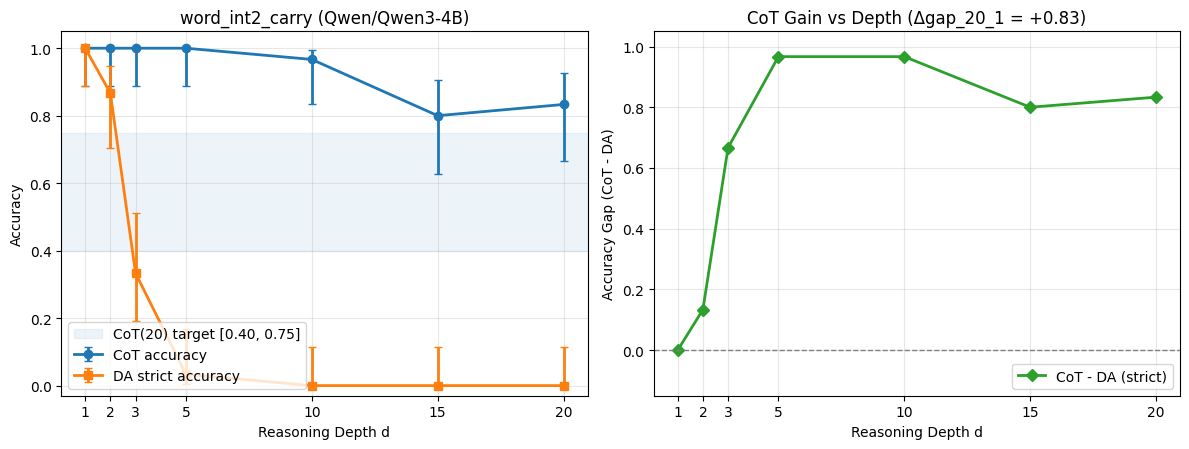

深度校准曲线已保存至：/content/taskA_word/Experiments/task_a_math_word/task_a_word_calibration.png


In [7]:
def wilson_ci(successes: int, n: int, z: float = 1.959963984540054) -> list[float]:
    if n <= 0 or not (0 <= successes <= n):
        raise ValueError(f"无效二项计数: {successes}/{n}")
    p = successes / n
    denom = 1.0 + z * z / n
    center = (p + z * z / (2.0 * n)) / denom
    radius = z * math.sqrt(p * (1.0 - p) / n + z * z / (4.0 * n * n)) / denom
    return [round(max(0.0, center - radius), 4), round(min(1.0, center + radius), 4)]


def ca_trend_test(successes: list[int], totals: list[int], scores: list[int] | tuple[int, ...]) -> dict:
    n = sum(totals)
    p = sum(successes) / n
    mean_s = sum(t * s for t, s in zip(totals, scores)) / n
    var = p * (1.0 - p) * sum(t * (s - mean_s) ** 2 for t, s in zip(totals, scores))
    if var <= 0:
        return {"z": 0.0, "p_two_sided": 1.0, "testable": False}
    z = sum((s - mean_s) * (x - t * p) for x, t, s in zip(successes, totals, scores)) / math.sqrt(var)
    return {"z": round(z, 6), "p_two_sided": round(math.erfc(abs(z) / math.sqrt(2.0)), 8), "testable": True}


def summarize_probe(rows: list[dict]) -> dict:
    n = len(rows)
    strict_hits = sum(int(r["strict_da_ok"]) for r in rows)
    all_hits = sum(int(r["answer_ok"]) for r in rows)
    leaks = sum(int(not r["da_compliant"]) for r in rows)
    echos = sum(int(r["echo_initial"]) for r in rows)
    p1_strict = strict_hits / n
    return {
        "config_name": rows[0]["config_name"],
        "n": n,
        "strict_correct": strict_hits,
        "strict_p1": round(p1_strict, 4),
        "strict_wilson95": wilson_ci(strict_hits, n),
        "overall_correct": all_hits,
        "overall_p1": round(all_hits / n, 4),
        "da_leak_rate": round(leaks / n, 4),
        "echo_initial_rate": round(echos / n, 4),
        "parse_fail_rate": round(sum(int(not r["parse_ok"]) for r in rows) / n, 4),
        "trunc_rate": round(sum(int(r["trunc"]) for r in rows) / n, 4),
        "mean_tokens": round(sum(r["n_tokens"] for r in rows) / n, 2),
        "in_da1_target_80_98": 0.80 <= p1_strict <= 0.98,
        "in_heuristic_p1_window": 0.955 <= p1_strict <= 0.986,
    }


def summarize_screen_cot20(rows: list[dict]) -> dict:
    n = len(rows)
    hits = sum(int(r["answer_ok"]) for r in rows)
    acc = hits / n
    return {
        "config_name": rows[0]["config_name"],
        "d": 20,
        "n": n,
        "correct": hits,
        "cot20_acc": round(acc, 4),
        "wilson95": wilson_ci(hits, n),
        "mean_tokens": round(sum(r["n_tokens"] for r in rows) / n, 1),
        "trunc_rate": round(sum(int(r["trunc"]) for r in rows) / n, 4),
        "in_cot20_hard_window": 0.40 <= acc <= 0.75,
    }


def summarize_slope(rows: list[dict], depths: tuple[int, ...] = D_LIST) -> dict:
    groups = defaultdict(list)
    for r in rows:
        groups[(r["d"], r["mode"])].append(r)

    n_per = len(groups[(depths[0], "DA")])
    table = []
    paired_diffs = {}
    cot_errors = []

    for d in depths:
        da_map = {r["qid"]: r for r in groups[(d, "DA")]}
        cot_map = {r["qid"]: r for r in groups[(d, "CoT")]}
        if len(da_map) != n_per or set(da_map) != set(cot_map):
            raise ValueError(f"d={d} 的 DA / CoT 样本未对齐或数量不足 {n_per}")

        # gap 使用严格 DA 口径对照 CoT 正确率
        qids_sorted = sorted(da_map)
        paired_diffs[d] = [int(cot_map[qid]["answer_ok"]) - int(da_map[qid]["strict_da_ok"]) for qid in qids_sorted]

        da_rows = [da_map[qid] for qid in qids_sorted]
        cot_rows = [cot_map[qid] for qid in qids_sorted]
        da_strict_hits = sum(int(r["strict_da_ok"]) for r in da_rows)
        da_all_hits = sum(int(r["answer_ok"]) for r in da_rows)
        cot_hits = sum(int(r["answer_ok"]) for r in cot_rows)

        for r in cot_rows:
            if not r["answer_ok"]:
                step_diff = r["cot_step_lines"] - d
                err_type = (
                    "truncation" if r["trunc"]
                    else "parse_fail" if not r["parse_ok"]
                    else "step_count_mismatch" if r["cot_step_lines"] > 0 and step_diff != 0
                    else "arithmetic_or_sign_error"
                )
                cot_errors.append({
                    "qid": r["qid"],
                    "d": d,
                    "i": r["i"],
                    "gold": r["gold"],
                    "predicted": r["predicted"],
                    "cot_step_lines": r["cot_step_lines"],
                    "error_type": err_type,
                })

        table.append({
            "d": d,
            "n": n_per,
            "DA": {
                "strict_correct": da_strict_hits,
                "strict_accuracy": round(da_strict_hits / n_per, 4),
                "strict_wilson95": wilson_ci(da_strict_hits, n_per),
                "overall_correct": da_all_hits,
                "overall_accuracy": round(da_all_hits / n_per, 4),
                "leak_rate": round(sum(int(not r["da_compliant"]) for r in da_rows) / n_per, 4),
                "echo_initial_rate": round(sum(int(r["echo_initial"]) for r in da_rows) / n_per, 4),
                "trunc_rate": round(sum(int(r["trunc"]) for r in da_rows) / n_per, 4),
                "mean_tokens": round(sum(r["n_tokens"] for r in da_rows) / n_per, 2),
            },
            "CoT": {
                "correct": cot_hits,
                "accuracy": round(cot_hits / n_per, 4),
                "wilson95": wilson_ci(cot_hits, n_per),
                "trunc_rate": round(sum(int(r["trunc"]) for r in cot_rows) / n_per, 4),
                "parse_fail_rate": round(sum(int(not r["parse_ok"]) for r in cot_rows) / n_per, 4),
                "mean_tokens": round(sum(r["n_tokens"] for r in cot_rows) / n_per, 1),
            },
            "gap": round(sum(paired_diffs[d]) / n_per, 4),
        })

    ca_da = ca_trend_test([row["DA"]["strict_correct"] for row in table], [n_per] * len(depths), depths)
    ca_cot = ca_trend_test([row["CoT"]["correct"] for row in table], [n_per] * len(depths), depths)

    d_min, d_max = depths[0], depths[-1]
    rng = random.Random(SEED)
    boots = sorted(
        sum(rng.choices(paired_diffs[d_max], k=n_per)) / n_per
        - sum(rng.choices(paired_diffs[d_min], k=n_per)) / n_per
        for _ in range(5000)
    )
    gap_growth = round(table[-1]["gap"] - table[0]["gap"], 4)
    da1_acc = table[0]["DA"]["strict_accuracy"]
    da20_acc = table[-1]["DA"]["strict_accuracy"]
    cot20_acc = table[-1]["CoT"]["accuracy"]

    checks = {
        "da1_descriptive_80_95": 0.80 <= da1_acc <= 0.95,
        "da1_healthy_ge_80": da1_acc >= 0.80,
        "cot20_hard_target_40_75": 0.40 <= cot20_acc <= 0.75,
        "da20_floor_le_10": da20_acc <= 0.10,
        "gap_growth_ge_30": gap_growth >= 0.30 - 1e-12,
        "cot_decreasing_ca_p_lt_001": ca_cot["z"] < 0 and ca_cot["p_two_sided"] < 0.01,
        "da_decreasing_ca_p_lt_001": ca_da["z"] < 0 and ca_da["p_two_sided"] < 0.01,
    }
    err_counts = dict(Counter(e["error_type"] for e in cot_errors))
    evidence = [
        {"id": r["id"], "text": r["text"], "strict_da_ok": r["strict_da_ok"], "answer_ok": r["answer_ok"], "trunc": r["trunc"]}
        for r in sorted(rows, key=lambda x: x["id"])
    ]
    return {
        "config_name": rows[0]["config_name"],
        "model_id": rows[0]["run_meta"]["model_id"],
        "model_commit": rows[0]["run_meta"]["model_commit"],
        "prompt_version": PROMPT_VERSION,
        "depths": list(depths),
        "n_per_depth": n_per,
        "table": table,
        "ca_trends": {"DA_strict": ca_da, "CoT": ca_cot},
        "gap20_minus_gap1": gap_growth,
        "gap_delta_paired_bootstrap95": [round(boots[124], 4), round(boots[4874], 4)],
        "checks": checks,
        "cot_error_breakdown": err_counts,
        "cot_error_samples": cot_errors[:25],
        "evidence_digest": digest(evidence),
        "manual_review_required": True,
    }


def print_slope_table(summary: dict) -> None:
    print(f"\n===== 斜率校准汇总：{summary['config_name']} | 模型：{summary['model_id']} =====")
    header = f"{'d':>3} | {'DA(strict)':>10} | {'DA 95% CI':>15} | {'DA leak':>7} | {'CoT':>8} | {'CoT 95% CI':>15} | {'gap':>6}"
    print(header)
    print("-" * len(header))
    for row in summary["table"]:
        da_ci = f"[{row['DA']['strict_wilson95'][0]:.2f}, {row['DA']['strict_wilson95'][1]:.2f}]"
        cot_ci = f"[{row['CoT']['wilson95'][0]:.2f}, {row['CoT']['wilson95'][1]:.2f}]"
        print(
            f"{row['d']:>3} | {row['DA']['strict_accuracy']:>10.2%} | {da_ci:>15} | "
            f"{row['DA']['leak_rate']:>7.1%} | {row['CoT']['accuracy']:>8.2%} | {cot_ci:>15} | {row['gap']:>+6.2f}"
        )
    print("-" * len(header))
    print(
        f"gap(20) - gap(1) = {summary['gap20_minus_gap1']:+.2f} "
        f"(配对 Bootstrap 95% CI: {summary['gap_delta_paired_bootstrap95']})"
    )
    print(f"CA 趋势检验 (CoT 随深度下降): z={summary['ca_trends']['CoT']['z']:.3f}, p={summary['ca_trends']['CoT']['p_two_sided']:.4g}")
    print(f"CA 趋势检验 (DA  随深度下降): z={summary['ca_trends']['DA_strict']['z']:.3f}, p={summary['ca_trends']['DA_strict']['p_two_sided']:.4g}")
    print("CoT 错误类型分布：", summary["cot_error_breakdown"])
    print("指标门控核对：", json.dumps(summary["checks"], ensure_ascii=False))
    print("\n[重要提醒] 按 task.md A.0 规范：请开发者务必对上述校准曲线及原文样本进行人工审查，确认无误后再生成正式 3000 题！")


def plot_calibration_curves(summary: dict, plot_path: Path | None = None) -> None:
    import matplotlib.pyplot as plt
    plot_path = Path(plot_path or PLOT_PATH)
    ds = [r["d"] for r in summary["table"]]
    da_y = [r["DA"]["strict_accuracy"] for r in summary["table"]]
    da_lo = [r["DA"]["strict_accuracy"] - r["DA"]["strict_wilson95"][0] for r in summary["table"]]
    da_hi = [r["DA"]["strict_wilson95"][1] - r["DA"]["strict_accuracy"] for r in summary["table"]]

    cot_y = [r["CoT"]["accuracy"] for r in summary["table"]]
    cot_lo = [r["CoT"]["accuracy"] - r["CoT"]["wilson95"][0] for r in summary["table"]]
    cot_hi = [r["CoT"]["wilson95"][1] - r["CoT"]["accuracy"] for r in summary["table"]]
    gaps = [r["gap"] for r in summary["table"]]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    ax1, ax2 = axes
    ax1.errorbar(ds, cot_y, yerr=[cot_lo, cot_hi], marker="o", lw=2, capsize=3, label="CoT accuracy")
    ax1.errorbar(ds, da_y, yerr=[da_lo, da_hi], marker="s", lw=2, capsize=3, label="DA strict accuracy")
    ax1.axhspan(0.40, 0.75, color="tab:blue", alpha=0.08, label="CoT(20) target [0.40, 0.75]")
    ax1.set_title(f"{summary['config_name']} ({summary['model_id']})")
    ax1.set_xlabel("Reasoning Depth d")
    ax1.set_ylabel("Accuracy")
    ax1.set_xticks(ds)
    ax1.set_ylim(-0.03, 1.05)
    ax1.grid(True, alpha=0.3)
    ax1.legend(loc="lower left")

    ax2.plot(ds, gaps, marker="D", color="tab:green", lw=2, label="CoT - DA (strict)")
    ax2.axhline(0.0, color="gray", ls="--", lw=1)
    ax2.set_title(f"CoT Gain vs Depth (Δgap_20_1 = {summary['gap20_minus_gap1']:+.2f})")
    ax2.set_xlabel("Reasoning Depth d")
    ax2.set_ylabel("Accuracy Gap (CoT - DA)")
    ax2.set_xticks(ds)
    ax2.set_ylim(-0.15, 1.05)
    ax2.grid(True, alpha=0.3)
    ax2.legend(loc="lower right")

    fig.tight_layout()
    plot_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(plot_path, dpi=160)
    plt.show()
    print(f"深度校准曲线已保存至：{plot_path}")


def prepare_split_questions(config_name: str, split: str, depths: tuple[int, ...], n_per_depth: int) -> list[dict]:
    cfg = CANDIDATES[config_name]
    raw = [make_question(cfg, d, i, split) for d in depths for i in range(n_per_depth)]
    q_path = WORK_DIR / f"questions_{config_name}_{split}.jsonl"
    return roundtrip_questions(q_path, raw)


def execute_calibration_stage(llm=None, tokenizer=None, SamplingParams=None, meta=None, result_path: Path | None = None):
    result_path = Path(result_path or RESULT_PATH)
    if RUN_STAGE == "offline":
        if result_path.is_file():
            existing = read_jsonl(result_path)
            slope_rows = [r for r in existing if r.get("stage") == "slope"]
            if slope_rows:
                by_cfg = defaultdict(list)
                for r in slope_rows:
                    by_cfg[r["config_name"]].append(r)
                for cfg_name, r_list in by_cfg.items():
                    if len(r_list) == len(D_LIST) * N_SLOPE * 2:
                        s = summarize_slope(r_list)
                        print_slope_table(s)
        else:
            print("offline 模式：本地尚无已跑完的 GPU 校准结果文件；可在 Colab 选择 L4/T4 GPU 运行 search 阶段。")
        return None

    if llm is None:
        llm, tokenizer, SamplingParams, meta = load_vllm_engine()

    if RUN_STAGE == "diagnostic":
        diag_qs = prepare_split_questions(SELECTED, "diagnostic", (1, 2, 5), 8)
        jobs = make_jobs(diag_qs, "diagnostic", ("DA", "CoT"), meta)
        rows = run_jobs(jobs, llm, tokenizer, SamplingParams, out_path=DIAGNOSTIC_PATH)
        by_mode = {
            m: {
                "n": len([r for r in rows if r["mode"] == m]),
                "strict_acc": round(sum(int(r["strict_da_ok"]) for r in rows if r["mode"] == m) / max(1, len(diag_qs)), 4),
                "leak_rate": round(sum(int(not r["da_compliant"]) for r in rows if r["mode"] == m) / max(1, len(diag_qs)), 4),
            }
            for m in ("DA", "CoT")
        }
        report = {"config_name": SELECTED, "by_mode": by_mode, "run_meta": meta}
        write_json(DIAGNOSTIC_REPORT_PATH, report)
        print("诊断完成：", json.dumps(by_mode, ensure_ascii=False))
        return report

    if RUN_STAGE == "probe":
        reports = {}
        for cfg_name in PROBE_CANDIDATES:
            p_qs = prepare_split_questions(cfg_name, "probe", (1,), N_PROBE)
            p_jobs = make_jobs(p_qs, "probe", ("DA",), meta)
            p_rows = run_jobs(p_jobs, llm, tokenizer, SamplingParams, out_path=result_path)
            rep = summarize_probe(p_rows)
            reports[cfg_name] = rep
            print(f"[Probe {cfg_name}] strict DA(1) = {rep['strict_p1']:.2%} (95% CI {rep['strict_wilson95']}), leak={rep['da_leak_rate']:.1%}")
        write_json(PROBE_REPORT_PATH, reports)
        return reports

    if RUN_STAGE == "slope":
        p_qs = prepare_split_questions(SELECTED, "probe", (1,), N_PROBE)
        p_jobs = make_jobs(p_qs, "probe", ("DA",), meta)
        idx_existing = index_results(result_path)
        if all(j["id"] in idx_existing for j in p_jobs):
            p_rep = summarize_probe([idx_existing[j["id"]] for j in p_jobs])
            if not p_rep["in_da1_target_80_98"] and not PROBE_OVERRIDE_REASON:
                raise RuntimeError(f"{SELECTED} 的 DA(1)={p_rep['strict_p1']:.2%} 不在 [0.80, 0.98] 内；如确需强跑请填写 PROBE_OVERRIDE_REASON。")
        elif not PROBE_OVERRIDE_REASON:
            raise RuntimeError(f"尚未发现 {SELECTED} 的 100 条探针记录；请先运行 probe/search，或填写 PROBE_OVERRIDE_REASON。")

        s_qs = prepare_split_questions(SELECTED, "slope", D_LIST, N_SLOPE)
        s_jobs = make_jobs(s_qs, "slope", ("DA", "CoT"), meta)
        s_rows = run_jobs(s_jobs, llm, tokenizer, SamplingParams, out_path=result_path)
        summary = summarize_slope(s_rows)
        summary["probe_override_reason"] = PROBE_OVERRIDE_REASON or None
        write_json(SLOPE_REPORT_PATH, summary)
        print_slope_table(summary)
        plot_calibration_curves(summary)
        return summary

    # ---- RUN_STAGE == "search"：双向自适应探针 + CoT(20) 锚定 + 独立 7 深度斜率验证 ----
    trace_log = []
    evaluated = {}

    def eval_probe(cfg_name: str) -> dict:
        qs = prepare_split_questions(cfg_name, "probe", (1,), N_PROBE)
        rows = run_jobs(make_jobs(qs, "probe", ("DA",), meta), llm, tokenizer, SamplingParams, out_path=result_path)
        rep = summarize_probe(rows)
        print(
            f"[Search Probe | {cfg_name}] strict DA(1)={rep['strict_p1']:.2%} "
            f"(CI {rep['strict_wilson95']}), leak={rep['da_leak_rate']:.1%}, echo={rep['echo_initial_rate']:.1%}"
        )
        return rep

    def eval_screen(cfg_name: str) -> dict:
        qs = prepare_split_questions(cfg_name, "screen", (20,), N_SCREEN_COT20)
        rows = run_jobs(make_jobs(qs, "screen", ("CoT",), meta), llm, tokenizer, SamplingParams, out_path=result_path)
        rep = summarize_screen_cot20(rows)
        print(f"[Search Screen | {cfg_name}] CoT(20)={rep['cot20_acc']:.2%} (CI {rep['wilson95']}), avg_tok={rep['mean_tokens']}")
        return rep

    start_idx = SEARCH_LADDER.index(SEARCH_START)
    p_start = eval_probe(SEARCH_START)
    evaluated[SEARCH_START] = {"probe": p_start, "screen": None}

    chosen_cfg = None
    decision_reason = ""

    if p_start["strict_p1"] < 0.80:
        trace_log.append(f"{SEARCH_START} 的 DA(1)={p_start['strict_p1']:.2%} < 0.80，下探更轻量档 word_int1_easy")
        for idx in range(start_idx - 1, -1, -1):
            cand = SEARCH_LADDER[idx]
            p_cand = eval_probe(cand)
            s_cand = eval_screen(cand) if p_cand["strict_p1"] >= 0.70 else None
            evaluated[cand] = {"probe": p_cand, "screen": s_cand}
            if p_cand["strict_p1"] >= 0.80:
                chosen_cfg = cand
                decision_reason = f"{SEARCH_START} DA(1) 偏低，下探至 {cand} 后 DA(1)={p_cand['strict_p1']:.2%} 达标"
                break
        if chosen_cfg is None:
            chosen_cfg = max(evaluated, key=lambda k: evaluated[k]["probe"]["strict_p1"])
            decision_reason = f"所有已测档位 DA(1) 均低于 0.80，取最高档 {chosen_cfg} 进行诊断性斜率评估"
    else:
        s_start = eval_screen(SEARCH_START)
        evaluated[SEARCH_START]["screen"] = s_start
        if 0.40 <= s_start["cot20_acc"] <= 0.75:
            chosen_cfg = SEARCH_START
            decision_reason = f"{SEARCH_START} 同时满足 DA(1)={p_start['strict_p1']:.2%} ≥ 0.80 且 CoT(20)={s_start['cot20_acc']:.2%} ∈ [0.40, 0.75]"
        elif s_start["cot20_acc"] < 0.40:
            trace_log.append(f"{SEARCH_START} 的 CoT(20)={s_start['cot20_acc']:.2%} < 0.40，检查更易档 word_int1_easy")
            if start_idx > 0:
                easy_cand = SEARCH_LADDER[start_idx - 1]
                p_easy = eval_probe(easy_cand)
                s_easy = eval_screen(easy_cand)
                evaluated[easy_cand] = {"probe": p_easy, "screen": s_easy}
                if p_easy["strict_p1"] >= 0.80 and abs(s_easy["cot20_acc"] - 0.575) < abs(s_start["cot20_acc"] - 0.575):
                    chosen_cfg = easy_cand
                    decision_reason = f"下探至 {easy_cand} 后 CoT(20)={s_easy['cot20_acc']:.2%} 更接近目标窗口中心"
            if chosen_cfg is None:
                chosen_cfg = SEARCH_START
                decision_reason = f"保留 {SEARCH_START} 进行完整斜率测量"
        else:
            prev_valid = SEARCH_START
            for idx in range(start_idx + 1, len(SEARCH_LADDER)):
                cand = SEARCH_LADDER[idx]
                trace_log.append(f"{prev_valid} 的 CoT(20) 偏高，上探更难档 {cand}")
                p_cand = eval_probe(cand)
                if p_cand["strict_p1"] < 0.80:
                    evaluated[cand] = {"probe": p_cand, "screen": None}
                    chosen_cfg = prev_valid
                    decision_reason = f"{cand} 的 DA(1)={p_cand['strict_p1']:.2%} < 0.80，回退锁定上一有效档 {prev_valid}"
                    break
                s_cand = eval_screen(cand)
                evaluated[cand] = {"probe": p_cand, "screen": s_cand}
                if 0.40 <= s_cand["cot20_acc"] <= 0.75:
                    chosen_cfg = cand
                    decision_reason = f"上探至 {cand} 命中目标窗口：DA(1)={p_cand['strict_p1']:.2%}, CoT(20)={s_cand['cot20_acc']:.2%}"
                    break
                if s_cand["cot20_acc"] < 0.40:
                    prev_cot = evaluated[prev_valid]["screen"]["cot20_acc"]
                    chosen_cfg = cand if abs(s_cand["cot20_acc"] - 0.575) <= abs(prev_cot - 0.575) else prev_valid
                    decision_reason = f"{prev_valid} 与 {cand} 跨过 [0.40, 0.75] 窗口，选取更接近窗口中心的 {chosen_cfg}"
                    break
                prev_valid = cand
            if chosen_cfg is None:
                chosen_cfg = prev_valid
                decision_reason = f"已测至最高难度档 {chosen_cfg}（DA(1) 仍 ≥ 0.80），选定该档执行完整斜率校准"

    print(f"\n>>> 搜索决策：{decision_reason} -> 开始执行 {chosen_cfg} 的独立 7 深度斜率验证（{len(D_LIST)*N_SLOPE*2} 条）...")
    s_qs = prepare_split_questions(chosen_cfg, "slope", D_LIST, N_SLOPE)
    s_rows = run_jobs(make_jobs(s_qs, "slope", ("DA", "CoT"), meta), llm, tokenizer, SamplingParams, out_path=result_path)
    slope_rep = summarize_slope(s_rows)
    slope_rep["search_decision"] = decision_reason

    search_summary = {
        "search_start": SEARCH_START,
        "ladder": list(SEARCH_LADDER),
        "trace_log": trace_log,
        "evaluated": evaluated,
        "selected_candidate": chosen_cfg,
        "decision_reason": decision_reason,
        "slope_summary": slope_rep,
    }
    write_json(PROBE_REPORT_PATH, {k: v["probe"] for k, v in evaluated.items()})
    write_json(SEARCH_REPORT_PATH, search_summary)
    write_json(SLOPE_REPORT_PATH, slope_rep)
    print_slope_table(slope_rep)
    plot_calibration_curves(slope_rep)
    return search_summary


CALIBRATION_OUTPUT = execute_calibration_stage()


## 9. 人工审查门控、正式 3000 题生成与结果打包导出

### 人工批准模板（在校准结果审查通过后创建 `task_a_word_human_review.json`）
```json
{
  "approved": true,
  "reviewer": "Ziwei Wang",
  "reviewed_at": "2026-11-26",
  "selected_candidate": "word_int2_carry",
  "evidence_digest": "<填入 task_a_word_summary.json 中的 evidence_digest>",
  "notes": "人工核查各深度严格 DA 正确率、CoT 错误样本与趋势后批准生成正式 3000 题。"
}
```

In [8]:
def generate_formal_word_dataset(
    selected_name: str,
    slope_summary: dict,
    review: dict,
    out_path: Path | None = None,
    calib_path: Path | None = None,
) -> dict:
    out_path = Path(out_path or DATA_PATH)
    calib_path = Path(calib_path or RESULT_PATH)
    if not review or review.get("approved") is not True:
        raise RuntimeError("缺少有效人工批准（approved=True）；按 task.md A.0 规范拒绝自动生成正式数据集。")
    if review.get("selected_candidate") != selected_name:
        raise ValueError("人工批准中的候选名与当前选定候选不一致")
    if review.get("evidence_digest") != slope_summary.get("evidence_digest"):
        raise ValueError("人工批准绑定的校准结果指纹（evidence_digest）不匹配；请重新核对最新校准结果")
    if slope_summary.get("model_id") != "Qwen/Qwen3-4B":
        raise ValueError("正式定题必须基于 Qwen/Qwen3-4B 的真实校准结果")

    cfg = CANDIDATES[selected_name]
    formal_rows = []
    for d in range(1, 21):
        for i in range(N_FINAL):
            formal_rows.append(make_question(cfg, d=d, i=i, split="formal", kind="serial", w=1))
    for w in range(1, 11):
        for i in range(N_FINAL):
            formal_rows.append(make_question(cfg, d=(1 if w == 1 else 2), i=i, split="formal", kind="parallel", w=w))

    # 全量独立复算、去重、与校准集/fewshot 零重叠核验
    for row in formal_rows:
        verify_word_question(row)

    assert len(formal_rows) == 20 * N_FINAL + 10 * N_FINAL
    assert len({r["qid"] for r in formal_rows}) == len(formal_rows)
    assert len({r["q"] for r in formal_rows}) == len(formal_rows)

    calib_rows = read_jsonl(calib_path)
    calib_qids = {r["qid"] for r in calib_rows}
    calib_texts = {r["question"]["q"] for r in calib_rows}
    fewshot_texts = {ex["user"] for w_k in (1, 2) for ex in make_fewshot_examples(cfg, width=w_k)}
    assert not (calib_qids & {r["qid"] for r in formal_rows}), "正式题与校准题 qid 重叠"
    assert not (calib_texts & {r["q"] for r in formal_rows}), "正式题与校准题题干重叠"
    assert not (fewshot_texts & {r["q"] for r in formal_rows}), "正式题与 few-shot 示例重叠"

    reloaded = roundtrip_questions(out_path, formal_rows)
    assert len(reloaded) == len(formal_rows)
    data_sha = hashlib.sha256(Path(out_path).read_bytes()).hexdigest()

    manifest = {
        "dataset_path": str(Path(out_path).relative_to(ROOT)) if Path(out_path).is_relative_to(ROOT) else str(out_path),
        "sha256": data_sha,
        "version": VERSION,
        "prompt_version": PROMPT_VERSION,
        "seed": SEED,
        "selected_candidate": selected_name,
        "config": asdict(cfg),
        "counts": {
            "serial": 20 * N_FINAL,
            "parallel": 10 * N_FINAL,
            "total": len(formal_rows),
        },
        "calibration_model": slope_summary["model_id"],
        "calibration_model_commit": slope_summary["model_commit"],
        "evidence_digest": slope_summary["evidence_digest"],
        "human_review": review,
        "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    }
    manifest_path = Path(out_path).with_suffix(".manifest.json")
    write_json(manifest_path, manifest)
    write_json(FINAL_VALIDATION_PATH, {"ok": True, "total_verified": len(formal_rows), "sha256": data_sha})
    print(f"正式 3000 题已生成并通过全量独立复算：{out_path} (SHA256={data_sha})")
    return manifest


def export_calibration_package(zip_path: Path | None = None) -> Path | None:
    zip_path = Path(zip_path or EXPORT_ZIP_PATH)
    artifacts = [
        p for p in (
            RESULT_PATH,
            DIAGNOSTIC_PATH,
            PROBE_REPORT_PATH,
            SEARCH_REPORT_PATH,
            SLOPE_REPORT_PATH,
            DIAGNOSTIC_REPORT_PATH,
            PLOT_PATH,
            REVIEW_PATH,
            FINAL_VALIDATION_PATH,
        )
        if p.is_file()
    ]
    if not artifacts:
        print("当前无可导出的校准结果文件。")
        return None

    manifest = {
        "exported_at_utc": datetime.now(timezone.utc).isoformat(),
        "run_stage": RUN_STAGE,
        "version": VERSION,
        "prompt_version": PROMPT_VERSION,
        "files": [
            {
                "relpath": str(p.relative_to(ROOT)) if p.is_relative_to(ROOT) else p.name,
                "bytes": p.stat().st_size,
                "sha256": hashlib.sha256(p.read_bytes()).hexdigest(),
            }
            for p in artifacts
        ],
    }
    write_json(EXPORT_MANIFEST_PATH, manifest)
    artifacts.append(EXPORT_MANIFEST_PATH)

    zip_path.parent.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=9) as zf:
        for p in artifacts:
            arcname = str(p.relative_to(ROOT)) if p.is_relative_to(ROOT) else p.name
            zf.write(p, arcname=arcname)
    zip_bytes = zip_path.read_bytes()
    print(f"结果压缩包已生成：{zip_path}（共 {len(artifacts)} 个文件，{len(zip_bytes)/1024:.1f} KiB）")

    # 渲染内联 Base64 下载按钮：既防止浏览器拦截后台自动下载，也能随 Colab「保存到 GitHub」一并保存原始压缩包
    if len(zip_bytes) <= 5 * 1024 * 1024 and RUN_STAGE != "offline":
        import base64
        from IPython.display import HTML, display
        b64 = base64.b64encode(zip_bytes).decode("ascii")
        display(HTML(
            f'<div style="margin:10px 0;padding:10px;border:1px solid #2ea043;border-radius:6px;">'
            f'<b>校准结果包已就绪：</b> '
            f'<a download="task_a_word_results.zip" href="data:application/zip;base64,{b64}" '
            f'style="font-weight:bold;color:#1a7f37;">点击此处手动下载 task_a_word_results.zip ({len(zip_bytes)/1024:.1f} KiB)</a>'
            f'（若直接将本 Notebook 保存到 GitHub，压缩包也会随此输出一并提交）</div>'
        ))

    if AUTO_DOWNLOAD and "google.colab" in sys.modules and RUN_STAGE != "offline":
        try:
            from google.colab import files
            files.download(str(zip_path))
        except Exception as exc:
            print(f"浏览器自动下载未触发（{exc}），请点击上方绿色链接手动下载或直接保存到 GitHub。")
    return zip_path


if GENERATE_FINAL:
    if not SLOPE_REPORT_PATH.is_file():
        raise RuntimeError("未找到斜率汇总文件 task_a_word_summary.json，无法生成正式数据集。")
    _slope_rep = json.loads(SLOPE_REPORT_PATH.read_text(encoding="utf-8"))
    _rev = json.loads(REVIEW_PATH.read_text(encoding="utf-8")) if REVIEW_PATH.is_file() else REVIEW
    generate_formal_word_dataset(_slope_rep["config_name"], _slope_rep, _rev)


# 离线端到端回归测试（在临时目录用 Mock 引擎完整演练断点续跑 + 斜率统计 + 人工审核门控，绝不写入正式路径）
def run_offline_pipeline_regression() -> None:
    class MockOutputItem:
        def __init__(self, text):
            self.text = text
            self.token_ids = [1, 2, 3]
            self.finish_reason = "stop"

    class MockRequestOutput:
        def __init__(self, text, prompt_len):
            self.outputs = [MockOutputItem(text)]
            self.prompt_token_ids = [0] * prompt_len

    class MockSamplingParams:
        def __init__(self, **kwargs):
            self.kwargs = kwargs

    class MockTokenizer:
        def apply_chat_template(self, messages, tokenize=False, add_generation_prompt=False, continue_final_message=False, enable_thinking=True):
            body = "\n".join(f"{m['role']}:{m['content']}" for m in messages)
            if add_generation_prompt:
                body += "\nassistant:<think>\n\n</think>\n\n"
            return body

        def encode(self, text, add_special_tokens=False):
            return [0] * max(1, len(text) // 4)

    with tempfile.TemporaryDirectory() as tmp:
        tmp_dir = Path(tmp)
        mock_tok = MockTokenizer()
        mock_meta = {
            "tier": "B",
            "model_id": "Qwen/Qwen3-4B",
            "model_commit": "1cfa9a7208912126459214e8b04321603b3df60c",
            "loading": {"max_num_seqs": 32},
        }
        small_qs = [make_question(CANDIDATES["word_int2_carry"], d, i, "mock_slope") for d in (1, 5, 20) for i in range(4)]
        jobs = make_jobs(small_qs, "slope", ("DA", "CoT"), mock_meta)

        class GradedMockLLM:
            def generate(self, prompts, sp_list):
                res = []
                for p, sp in zip(prompts, sp_list):
                    matched = next(j for j in jobs if j["sampling_seed"] == sp.kwargs["seed"])
                    q = matched["question"]
                    gold = q["ans"]
                    if matched["mode"] == "DA":
                        txt = gold if q["d"] == 1 else "999999"
                    else:
                        txt = q["solution"] if (q["d"] < 20 or q["i"] < 2) else "Step 1: 1 + 1 = 2\n#### 999999"
                    res.append(MockRequestOutput(txt, len(mock_tok.encode(p))))
                return res

        mock_jsonl = tmp_dir / "mock_calib.jsonl"
        rows = run_jobs(jobs, GradedMockLLM(), mock_tok, MockSamplingParams, out_path=mock_jsonl, backend_name="mock")
        rows_cached = run_jobs(jobs, GradedMockLLM(), mock_tok, MockSamplingParams, out_path=mock_jsonl, backend_name="mock")
        assert rows == rows_cached
        s_rep = summarize_slope(rows, depths=(1, 5, 20))
        assert s_rep["table"][0]["DA"]["strict_accuracy"] == 1.0
        assert s_rep["table"][-1]["DA"]["strict_accuracy"] == 0.0
        assert s_rep["table"][-1]["CoT"]["accuracy"] == 0.5
        assert s_rep["gap20_minus_gap1"] == 0.5

        try:
            generate_formal_word_dataset("word_int2_carry", s_rep, {"approved": False}, out_path=tmp_dir / "formal.jsonl", calib_path=mock_jsonl)
            raise AssertionError("未批准时不应允许生成正式数据集")
        except RuntimeError:
            pass
    print("离线端到端流水线回归测试通过（断点续跑、斜率统计、人工审核门控全部正常）。")


if RUN_STAGE == "offline":
    run_offline_pipeline_regression()
else:
    export_calibration_package()


结果压缩包已生成：/content/taskA_word/work/task_a_math_word/task_a_word_results.zip（共 6 个文件，325.9 KiB）


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>